<a href="https://colab.research.google.com/github/cerenvar/meg-word-decoding/blob/main/notebooks/ip1_veri_hatti.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# İP-1 | LibriBrain100 Veri Erişimi, Veri Hattı ve Sızıntı Denetimi

**Proje:** MEG Sinyallerinden Dinlenen Kelimenin Çözümlenmesi (TÜBİTAK 2209-A)
**İş paketi:** İP-1 (1. ay) · Öneri Bölüm 2.1, 2.2 ve 3.1

Bu not defteri İP-1'in çıktılarını baştan sona, tek bir çalıştırmayla üretir:

| Çıktı | Öneri | Not defterindeki bölüm | Dosya |
|---|---|---|---|
| Veri erişim tablosu (oturum, dakika, kelime örneği) | Hedef 1, 2.1 | Bölüm 5 | `data_access.csv` |
| Olay dosyalarının bütünlüğü ve zaman çakışmaları | 2.1, 2.2 | Bölüm 5 | `event_integrity.csv`, `timing_conflicts.csv` |
| 33 katılımcının veri keşfi ve kalite raporu | 2.1, 2.2/1, R5 | Bölüm 4, Bölüm 8 | `quality_report.csv`, `outlier_channels.csv` |
| 50 sınıfın frekans dağılımı | 3.1 | Bölüm 5 | `class_frequencies.csv` |
| Standart ayrımlar ve geliştirme/değerlendirme ayrımı | 2.1, R2 | Bölüm 3, Bölüm 6 | `participant_roles.json`, `adaptation_subsets.csv` |
| Otomatik sızıntı testleri | Hedef 1, 2.2 | Bölüm 7 | `leakage_tests.csv` |
| Önceden kesilmiş pencere arşivi ve normalizasyon parametreleri | 2.2/4–5 | Bölüm 8 | `windows_500ms_pT/`, `window_manifest.parquet` |
| Koşu süresi, bellek ön ölçümü ve güncellenmiş hesaplama planı | 2.7, 3.1 | Bölüm 9 | `benchmark.json` |
| Öneriden sapma kaydı | — | tüm bölümler | `deviations.csv` |

**Çalıştırma kuralı:** Not defteri her zaman *Çalışma zamanı → Yeniden başlat ve tümünü çalıştır* ile, yukarıdan aşağı çalıştırılır. Uzun süren adımlar (Bölüm 5, Bölüm 8) kaldığı yerden devam eder; Colab bağlantısı koparsa aynı hücre yeniden çalıştırılabilir.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## Bölüm 1 Ortam ve yapılandırma

Bütün sabitler, klasörler ve rastgele tohum bu bölümde tek yerde tanımlanır. Yeniden üretilebilirlik için kütüphane sürümleri ve Hugging Face veri depolarının o anki commit kimlikleri (`HF_REVISION`) kaydedilir; bundan sonraki tüm indirmeler bu commit'lere sabitlenir.



**Depolama:** Çıktılar ve pencere arşivi, ekiple paylaşılan Google Drive klasöründe (`MyDrive/MEG_2209A`) tutulur (`USE_DRIVE = True`). Colab oturumu kapansa da ilerleme korunur; uzun adımlar (Bölüm 5, Bölüm 8) kaldığı yerden devam eder. Ağır adımı (Bölüm 8) klasörün sahibi çalıştırmalıdır: paylaşılan klasöre yazılan dosyalar, yazan kişinin Drive kotasından düşer. Aynı anda yalnızca bir kişi Bölüm 8'i çalıştırmalıdır.

Aşağıdaki kurulum hücresini çalıştırdıktan sonra **çalışma zamanını yeniden başlatın**, ardından sonraki hücreden devam edin.

In [1]:
%pip install -q "pnpl==0.2.0"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.2 which is incompatible.


In [2]:
import ast
import difflib
import json
import platform
import random
import re
import sys
import time
from collections import Counter
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from huggingface_hub import HfApi, HfFileSystem, hf_hub_download
from huggingface_hub.utils import disable_progress_bars
from matplotlib.patches import Patch, Rectangle
from tqdm.auto import tqdm

from pnpl.competition.submission import load_vocabulary
from pnpl.datasets import LibriBrain100
from pnpl.datasets.libribrain100.base import normalize_corpus, normalize_subjects, select_records
from pnpl.datasets.libribrain100.constants import REPO_KEY_TO_ID
from pnpl.tasks import WordClassification

disable_progress_bars()
import logging
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)   # yeniden deneme uyarılarını gizle
pd.set_option("display.max_columns", 30)

# --- Sabitler (Öneri Bölüm 2.2) ---------------------------------------------
SEED = 2209
WINDOW_SEC = 0.5                    # birincil pencere; 1000/1500 ms İP-3'te
EXPECTED_SFREQ = 250.0
N_CHANNELS = 306
PREPROC = "bads+headpos+sss+notch+bp+ds"
HF_REPOS = ("pnpl/LibriBrain", "pnpl/LibriBrain2")
TARGET_SUBJECTS = list(range(1, 33))

USE_DRIVE = True

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/MEG_2209A")
else:
    PROJECT_DIR = Path("/content/MEG_2209A")
DATA_DIR = Path("/content/data/LibriBrain100")               # geçici ham veri (pilot)
OUT = PROJECT_DIR / "ip1"
ARCHIVE_DIR = PROJECT_DIR / "windows_500ms_pT"
for folder in (DATA_DIR, OUT, ARCHIVE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)


api = HfApi()
hffs = HfFileSystem()
# Veri sürümü sabittir: ara dosyalar ve arşiv bu sürümle üretildi. Yeni sürüme geçmek bilinçli bir karar olmalıdır.
HF_REVISION = {
    "pnpl/LibriBrain": "5a7c332b34fc7be329c4df3e527a41f67bfd878f",
    "pnpl/LibriBrain2": "78443d024480c66bf340073c69bef50af8d1d335",
}
latest_revision = {repo: api.dataset_info(repo).sha for repo in HF_REPOS}
newer = [repo for repo in HF_REPOS if latest_revision[repo] != HF_REVISION[repo]]
if newer:
    print("UYARI: Hugging Face'te daha yeni veri sürümü var:", newer, "— sabitlenen sürüm kullanılıyor.")

run_info = {
    "date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    **{pkg: version(pkg) for pkg in ("pnpl", "numpy", "pandas", "h5py", "torch", "huggingface_hub")},
    "hf_revision": HF_REVISION,
    "seed": SEED,
    "window_sec": WINDOW_SEC,
    "storage": "google_drive" if USE_DRIVE else "colab_local",
}
(OUT / "run_info.json").write_text(json.dumps(run_info, indent=2, ensure_ascii=False))

assert run_info["pnpl"] == "0.2.0", "PNPL sürümü sabitlenen sürümle aynı değil"
assert all(len(sha) == 40 for sha in HF_REVISION.values())
run_info

Mounted at /content/drive


{'date_utc': '2026-11-21T12:56:44+00:00',
 'python': '3.13.16',
 'platform': 'Linux-6.6.159+-x86_64-with-glibc2.39',
 'pnpl': '0.2.0',
 'numpy': '2.4.6',
 'pandas': '2.2.3',
 'h5py': '3.14.0',
 'torch': '2.14.1+cu130',
 'huggingface_hub': '1.33.0',
 'hf_revision': {'pnpl/LibriBrain': '5a7c332b34fc7be329c4df3e527a41f67bfd878f',
  'pnpl/LibriBrain2': '78443d024480c66bf340073c69bef50af8d1d335'},
 'seed': 2209,
 'window_sec': 0.5,
 'storage': 'google_drive'}

### Öneriden sapma kaydı

Araştırma önerisi değiştirilemediği için, uygulamada önerinin açık bıraktığı veya farklı uygulanan her nokta burada kayıt altına alınır. Bu tablo sonuç raporundaki "Öneriden sapmalar" bölümünün kaynağıdır.

In [3]:
DEVIATIONS = {}

def log_deviation(key, section, proposal_says, decision, reason):
    # Aynı anahtar yeniden kaydedilirse üzerine yazılır; hücreler tekrar çalıştırılabilir.
    DEVIATIONS[key] = {"section": section, "proposal": proposal_says,
                       "implementation": decision, "rationale": reason}
    pd.DataFrame(DEVIATIONS.values()).to_csv(OUT / "deviations.csv", index=False)

## Bölüm 2 Sözlük ve yardımcı fonksiyonlar

### 50 kelimelik sözlük

Görev, veri seti makalesinin Tablo 6'sındaki sabit 50 kelimenin sınıflandırılmasıdır. Sözlük, PNPL ile birlikte dağıtılan resmî dosyadan (`vocabulary.csv`) okunur ve makaledeki tabloyla birebir karşılaştırılır.

PNPL'nin `WordClassification` görevi bu sözlüğü **kullanmaz**: yüklenen kayıtlardaki tüm kelimeleri büyük/küçük harf ayırarak etiketler (tek bir kayıtta 1.000'i aşkın sınıf) ve sözlük dışındaki kelimeye sessizce `0` verir. Bu nedenle 50 sınıf etiketi her yerde bu bölümdeki `WORD_TO_LABEL` ile atanır.

Resmî dosyada "it’s" kıvrık kesme işaretiyle yazılmıştır; olay dosyalarındaki yazımla karşılaştırma yapabilmek için tüm kelimeler `norm_word` ile aynı biçime getirilir.

In [4]:
# Makale Tablo 6, sırasıyla
TABLE6_WORDS = '''
is the a to it i not was we be
he that have this they of there and are in
but will so all my for she were any really
at out our am it's had him an very has
do can time think good always new people as on
'''.split()

def norm_word(word) -> str:
    return str(word).strip().lower().replace("’", "'")

VOCAB = [norm_word(w) for w in load_vocabulary("primary")]
WORD_TO_LABEL = {word: label for label, word in enumerate(VOCAB)}

assert len(VOCAB) == len(set(VOCAB)) == 50
assert VOCAB == [norm_word(w) for w in TABLE6_WORDS], "PNPL sözlüğü makaledeki tabloyla aynı değil"

pd.DataFrame({"Etiket": range(50), "Kelime": VOCAB}).set_index("Etiket").T

Etiket,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,...,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49
Kelime,is,the,a,to,it,i,not,was,we,be,he,that,have,this,they,...,had,him,an,very,has,do,can,time,think,good,always,new,people,as,on


### Dosya erişimi ve pencere indeksi

* `hf_file` dosyayı sabitlenmiş commit'ten indirir.
* `h5_header` bir HDF5 kaydının yalnızca başlığını (örnekleme frekansı, örnek sayısı, kanal listesi) dosyanın tamamını indirmeden okur. Uzak okuma başarısız olursa dosyayı indirip okur.
* `build_window_index` bir olay dosyasından kelime başına bir satır üretir. Pencere başlangıcı PNPL ile **aynı** formülle hesaplanır (`int(onset × sfreq)`); bu eşitlik Bölüm 4'te gerçek veriyle doğrulanır. PNPL, pencerenin kaydın sonuna sığıp sığmadığını denetlemez; kısaltılmış (ilk yarı / ilk çeyrek) kayıtlarda kayıt dışına taşan kelimeler kısa veya boş pencere üretir. `fits` sütunu bu pencereleri ayırır.
* Kelime süresi (`duration`) ve komşu kelimelere uzaklık (`gap_prev`, `gap_next`) İP-2'deki zamanlama kontrolleri için saklanır.

In [5]:
def hf_file(repo_id: str, path: str) -> str:
    return hf_hub_download(repo_id, path, repo_type="dataset", revision=HF_REVISION[repo_id])


def _attr_text(value) -> str:
    return value.decode() if isinstance(value, bytes) else str(value)


def _read_header(h5) -> dict:
    return {
        "sfreq": float(h5.attrs["sample_frequency"]),
        "n_samples": int(h5["data"].shape[1]),
        "n_channels": int(h5["data"].shape[0]),
        "dtype": str(h5["data"].dtype),
        "highpass": float(h5.attrs["highpass_cutoff"]),
        "lowpass": float(h5.attrs["lowpass_cutoff"]),
        "channel_names": _attr_text(h5.attrs["channel_names"]),
        "channel_types": _attr_text(h5.attrs["channel_types"]),
    }


HEADER_SOURCE = Counter()   # başlığın uzaktan mı, tam indirmeyle mi okunduğu


def h5_header(repo_id: str, path: str, attempts: int = 4) -> dict:
    remote = f"datasets/{repo_id}@{HF_REVISION[repo_id]}/{path}"
    for attempt in range(attempts):
        try:
            with hffs.open(remote, "rb") as fh, h5py.File(fh, "r") as h5:
                header = _read_header(h5)
            HEADER_SOURCE["uzak"] += 1
            return header
        except Exception:
            time.sleep(2 ** attempt)                      # 1, 2, 4, 8 sn bekleyip yeniden dene
    local = hf_file(repo_id, path)                        # son çare: dosyayı indir, oku, sil
    try:
        with h5py.File(local, "r") as h5:
            header = _read_header(h5)
        HEADER_SOURCE["tam_indirme"] += 1
        return header
    finally:
        Path(local).resolve().unlink(missing_ok=True)
        Path(local).unlink(missing_ok=True)


def read_events(tsv_path) -> pd.DataFrame:
    events = pd.read_csv(tsv_path, sep="\t", encoding="utf-8-sig")
    events.columns = events.columns.str.strip().str.lower()
    return events


def word_events(events: pd.DataFrame, onset_col: str) -> pd.DataFrame:
    if not {"kind", "segment", onset_col} <= set(events.columns):
        return events.iloc[0:0].assign(onset=pd.Series(dtype=float), segment=pd.Series(dtype=object))
    kind = events["kind"].astype("string").str.strip().str.lower()
    words = events.loc[kind.eq("word")].copy()
    words["onset"] = pd.to_numeric(words[onset_col], errors="coerce")
    words = words.dropna(subset=["segment", "onset"])
    return words.sort_values("onset", kind="stable")


def file_order_words(events: pd.DataFrame, onset_col: str) -> pd.DataFrame:
    # Kelimeler olay dosyasındaki sırayla (uyaranın gerçek sırası); zaman sıralaması yapılmaz.
    kind = events["kind"].astype("string").str.strip().str.lower()
    words = events.loc[kind.eq("word")].dropna(subset=["segment"])
    return pd.DataFrame({"word": words["segment"].map(norm_word).to_numpy(),
                         "onset": pd.to_numeric(words[onset_col], errors="coerce").to_numpy()})


def record_of(subject, task, session):
    return records.loc[records["subject"].eq(subject) & records["task"].eq(task)
                       & records["session"].eq(session), "record"].item()


def build_window_index(events, record_id, sfreq, n_samples, onset_col, window_sec=WINDOW_SEC):
    # Kelime başına bir satır; pencere sınırları örnek (sample) cinsindendir.
    words = word_events(events, onset_col)
    n_points = int(window_sec * sfreq)                     # PNPL: int((tmax - tmin) * sfreq)
    out = pd.DataFrame({
        "record": record_id,
        "event_row": words.index.to_numpy(),               # olay dosyasındaki satır = uyaran kimliği
        "onset": words["onset"].to_numpy(dtype=float),
        "duration": (pd.to_numeric(words["duration"], errors="coerce").to_numpy(dtype=float)
                     if "duration" in words else np.nan),
        "word": words["segment"].map(norm_word).to_numpy(),
    })
    out["gap_prev"] = out["onset"].diff()
    out["gap_next"] = -out["onset"].diff(-1)
    out["start"] = (out["onset"] * sfreq).astype(int)      # PNPL: int((onset + tmin) * sfreq)
    out["stop"] = out["start"] + n_points
    out["fits"] = (out["onset"] >= 0) & (out["stop"] <= n_samples)
    out["in_vocab"] = out["word"].isin(WORD_TO_LABEL)
    out["label"] = out["word"].map(WORD_TO_LABEL).astype("Int64")
    return out

## Bölüm 3 Kayıt envanteri ve standart veri ayrımları

LibriBrain100, iki Hugging Face deposunun (`pnpl/LibriBrain`, `pnpl/LibriBrain2`) birleşimidir. Bu bölümde:

1. İki deponun dosya listesi sabitlenmiş commit'ten alınır.
2. PNPL'nin resmî kayıt manifestindeki her kayıt (subj0'ın tüm kayıtları ve subj1–32'nin 11. ve 12. oturumları) bir MEG dosyası ve bir olay dosyasıyla eşleştirilir.
3. Standart ayrımların (train / validation / test) beklenen yapıda olduğu doğrulanır.

Bu aşamada dosya indirilmez; yalnızca dosya adları ve manifest kullanılır.

In [6]:
FILE_PATTERN = re.compile(
    r"sub-(?P<subject>\d+)_ses-(?P<session>\d+)_task-(?P<task>[^_]+)_run-(?P<run>[^_]+)"
    r"(?:_proc-(?P<proc>[^_]+))?(?:_desc-(?P<desc>[^_]+))?_(?P<kind>meg\.h5|events\.tsv)$"
)

rows = []
for repo in HF_REPOS:
    for path in api.list_repo_files(repo, repo_type="dataset", revision=HF_REVISION[repo]):
        match = FILE_PATTERN.search(Path(path).name)
        if match:
            rows.append({"repo": repo, "path": path, **match.groupdict()})

file_index = pd.DataFrame(rows)
print("Eşleşen dosya:", len(file_index))
display(file_index.groupby(["repo", "kind"]).size().unstack(fill_value=0))

Eşleşen dosya: 628


kind,events.tsv,meg.h5
repo,,
pnpl/LibriBrain,196,91
pnpl/LibriBrain2,206,135


In [7]:
manifest = select_records(subjects=normalize_subjects("all"), corpus=normalize_corpus("all"), partition=None)


def resolve_files(record):
    key = dict(subject=record.subject, session=record.session, task=record.task, run=record.run)
    same_run = file_index.loc[(file_index[list(key)] == pd.Series(key)).all(axis=1)]
    primary = REPO_KEY_TO_ID[record.repo]

    meg = same_run.loc[same_run["kind"].eq("meg.h5") & same_run["proc"].eq(PREPROC)]
    standard = meg.loc[meg["desc"].isna()]
    if len(standard):                                    # tam kayıt
        chosen, release = standard, "standart"
    else:                                                # kademeli sürüm (ilk yarı / ilk çeyrek)
        chosen = meg
        release = chosen["desc"].iloc[0] if len(chosen) == 1 else None
    chosen = chosen.sort_values("repo", key=lambda s: s.ne(primary))

    events = same_run.loc[same_run["kind"].eq("events.tsv")].sort_values("repo", key=lambda s: s.ne(primary))
    return {
        "meg_repo": chosen["repo"].iloc[0] if len(chosen) else None,
        "meg_path": chosen["path"].iloc[0] if len(chosen) else None,
        "tsv_repo": events["repo"].iloc[0] if len(events) else None,
        "tsv_path": events["path"].iloc[0] if len(events) else None,
        "release": release,
        "n_meg_candidates": len(chosen),
        "n_tsv_candidates": len(events),
    }


records = pd.DataFrame([
    {"record": "sub-{}_ses-{}_task-{}_run-{}".format(*r.run_key),
     "subject": int(r.subject), "session": int(r.session), "task": r.task, "run": r.run,
     "corpus": r.corpus, "partition": r.partition, **resolve_files(r)}
    for r in manifest
]).sort_values(["subject", "task", "session"]).reset_index(drop=True)

unresolved = records.loc[records["meg_path"].isna() | records["tsv_path"].isna() | records["release"].isna()]
print("Manifestteki kayıt:", len(records))
print("MEG ve olay dosyası eşleşen kayıt:", len(records) - len(unresolved))
assert unresolved.empty, unresolved[["record", "n_meg_candidates", "n_tsv_candidates"]]
assert records["record"].is_unique

Manifestteki kayıt: 226
MEG ve olay dosyası eşleşen kayıt: 226


In [8]:
subj0 = records.loc[records["subject"].eq(0)]
targets = records.loc[records["subject"].ge(1)]

print("subj0 kayıt sayısı:", len(subj0))
display(subj0.groupby(["corpus", "task"]).size().rename("Kayıt").to_frame().T)
display(subj0.groupby("partition").size().rename("Kayıt").to_frame().T)
display(subj0.loc[subj0["partition"].ne("train"), ["record", "partition"]])

# Beklenen yapı (Öneri 2.1)
assert len(subj0) == 162
assert subj0["partition"].value_counts().to_dict() == {"train": 156, "validation": 3, "test": 3}
sherlock_eval = subj0.loc[subj0["task"].eq("Sherlock1") & subj0["session"].isin([11, 12])]
assert sherlock_eval.set_index("session")["partition"].to_dict() == {11: "validation", 12: "test"}

assert len(targets) == 64
for session, partition in ((11, "validation"), (12, "test")):
    part = targets.loc[targets["session"].eq(session)]
    assert sorted(part["subject"]) == TARGET_SUBJECTS, f"ses-{session}: katılımcı eksik veya tekrarlı"
    assert part["partition"].eq(partition).all() and part["task"].eq("Sherlock1").all()
print("Standart ayrım yapısı doğrulandı.")

subj0 kayıt sayısı: 162


corpus      mocha podcasts  sherlock                                          \
task   MOCHATIMIT  TheMoth Sherlock1 Sherlock2 Sherlock3 Sherlock4 Sherlock5   
Kayıt           4       30        12        12        12        12        15   

corpus                                         timit  
task   Sherlock6 Sherlock7 Sherlock8 Sherlock9 TIMIT  
Kayıt         14        14        10        13    14

partition,test,train,validation
Kayıt,3,156,3


,record,partition
1,sub-0_ses-2_task-MOCHATIMIT_run-1,validation
2,sub-0_ses-3_task-MOCHATIMIT_run-1,test
14,sub-0_ses-11_task-Sherlock1_run-2,validation
15,sub-0_ses-12_task-Sherlock1_run-2,test
160,sub-0_ses-29_task-TheMoth_run-1,validation
161,sub-0_ses-30_task-TheMoth_run-1,test


Standart ayrım yapısı doğrulandı.


subj0'ın kayıtları dokuz Sherlock Holmes kitabını, TIMIT ve MOCHA-TIMIT cümlelerini ve Podcasts (The Moth; dosya adlarında `TheMoth`) kayıtlarını kapsar. Standart ayrımda doğrulama ve test bölümlerinin her biri üç kayıttan oluşur: Sherlock1'in 11. / 12. oturumu ile birer MOCHA-TIMIT ve TheMoth kaydı. Geri kalan 156 kayıt kaynak eğitim verisidir.

subj1–32 için ayrı bir eğitim bölümü yoktur: 11. oturum `validation`, 12. oturum `test` olarak tanımlanmıştır. Projede bu iki oturumun rolü, katılımcıların geliştirme / değerlendirme ayrımına göre Bölüm 6'da belirlenir.

Aşağıdaki tablo, hedef katılımcıların hangi dosya sürümüyle yayımlandığını gösterir. `standart` dışındaki sürümler (ilk yarı, ilk çeyrek), verinin kademeli olarak yayımlandığını gösterir ve Bölüm 6'daki senaryo kararının kanıtıdır.

In [9]:
release_table = targets.pivot(index="subject", columns="session", values="release")
display(release_table.T)
display(targets.groupby(["session", "release"]).size().rename("Kayıt").unstack(fill_value=0))

subject,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,...,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32
session,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
11,standart,standart,standart,standart,standart,standart,standart,standart,standart,standart,standart,standart,firsthalf,firsthalf,firsthalf,...,firsthalf,firsthalf,firsthalf,firsthalf,firsthalf,firstquarter,firstquarter,firstquarter,firstquarter,firstquarter,firstquarter,firstquarter,firstquarter,firstquarter,firstquarter
12,standart,standart,standart,standart,standart,standart,standart,standart,standart,standart,standart,standart,firsthalf,firsthalf,firsthalf,...,firsthalf,firsthalf,firsthalf,firsthalf,firsthalf,firstquarter,firstquarter,firstquarter,firstquarter,firstquarter,firstquarter,firstquarter,firstquarter,firstquarter,firstquarter


release,firsthalf,firstquarter,standart
session,,,
11,10,10,12
12,10,10,12


## Bölüm 4 Pilot kayıt: veri yapısı ve zaman ekseninin doğrulanması

İlk keşif için kaynak eğitimde kullanılacak subj0'ın tek bir Sherlock1 kaydı PNPL'nin `LibriBrain100` sınıfıyla yüklenir. Bu bölümde:

* MEG penceresinin boyutu, kanal türleri, örnekleme frekansı ve filtre bilgileri,
* olay dosyasındaki hangi zaman sütununun MEG zaman eksenine karşılık geldiği,
* Bölüm 2'deki pencere indeksinin PNPL'nin yüklediği pencerelerle birebir aynı olduğu

doğrulanır. Bu bölümde model eğitimi ve normalizasyon yapılmaz (`standardize=False`); PNPL'nin otomatik standardizasyonu, veri setine verilen tüm kayıtlar üzerinden hesaplandığı için test kayıtlarıyla birlikte kullanıldığında sızıntıya yol açar.

`WordClassification` nesnesi yalnızca pencereleri yüklemek için kullanılır; ürettiği etiketler kullanılmaz.

In [10]:
pilot_key = ("0", "1", "Sherlock1", "1")
word_task = WordClassification(tmin=0.0, tmax=WINDOW_SEC)

pilot = LibriBrain100(
    data_path=str(DATA_DIR),
    task=word_task,
    subjects="deep",
    corpus="sherlock",
    include_run_keys=[pilot_key],
    standardize=False,
    include_info=True,
    preload_files=False,
    preload_h5=False,
    download=True,
)

meg_signal, _, info = pilot[0]
print("Pilot kayıt:", pilot_key)
print("Kelime örneği (tüm kelimeler):", len(pilot))
print("Pencere boyutu (kanal × zaman):", tuple(meg_signal.shape), meg_signal.dtype)
print("Örnek bilgisi alanları:", list(info))

Pilot kayıt: ('0', '1', 'Sherlock1', '1')
Kelime örneği (tüm kelimeler): 2836
Pencere boyutu (kanal × zaman): (306, 125) torch.float32
Örnek bilgisi alanları: ['dataset', 'subject', 'session', 'task', 'run', 'onset']


In [11]:
pilot_h5_path = pilot.get_h5_path(*pilot_key)
pilot_tsv_path = pilot.get_events_path(*pilot_key)

with h5py.File(pilot_h5_path, "r") as h5:
    pilot_header = _read_header(h5)

sfreq = pilot_header["sfreq"]
channel_names = [c.strip() for c in pilot_header["channel_names"].split(",")]
channel_types = np.array([t.strip() for t in pilot_header["channel_types"].split(",")])

assert sfreq == EXPECTED_SFREQ
assert len(channel_names) == len(channel_types) == pilot_header["n_channels"] == N_CHANNELS

print(f"Örnekleme frekansı: {sfreq} Hz")
print(f"Kayıt süresi: {pilot_header['n_samples'] / sfreq / 60:.2f} dk")
print(f"Veri tipi: {pilot_header['dtype']}")
print(f"HDF5 filtre öznitelikleri: high-pass {pilot_header['highpass']} Hz, low-pass {pilot_header['lowpass']} Hz")
print("Kanal türleri:", dict(Counter(channel_types)))

Örnekleme frekansı: 250.0 Hz
Kayıt süresi: 18.53 dk
Veri tipi: float32
HDF5 filtre öznitelikleri: high-pass 0.10000000149011612 Hz, low-pass 125.0 Hz
Kanal türleri: {np.str_('mag'): 102, np.str_('grad'): 204}


Kayıt 102 manyetometre (`mag`, birim T) ve 204 gradiyometre (`grad`, birim T/m) olmak üzere 306 MEG kanalı içerir. Dosya adındaki işlem zinciri (`bads+headpos+sss+notch+bp+ds`), veri ekibinin uyguladığı bozuk kanal işleme, kafa konumu düzeltmesi, Signal Space Separation, çentik filtre, bant geçiren filtre ve alt örnekleme adımlarını gösterir; bu adımlar yeniden uygulanmaz.

**Not:** HDF5'teki `lowpass_cutoff` değeri 125 Hz, yani 250 Hz örneklemenin Nyquist frekansıdır. Bu öznitelik büyük olasılıkla alt örnekleme sonrası değeri tutar; bant geçiren filtrenin gerçek sınırları rapora veri seti dokümantasyonundan aktarılmalıdır.

### Zaman sütununun doğrulanması

Olay dosyalarında iki zaman sütunu bulunur: `timemeg` ve `timeds`. PNPL pencereyi `timemeg` ile keser. Aşağıdaki hücre iki sütunun farkını ölçer ve Bölüm 2'deki `build_window_index` fonksiyonunun PNPL'nin yüklediği pencerelerle birebir aynı pencereleri ürettiğini rastgele örneklerde doğrular. Bundan sonraki tüm sayımlar `ONSET_COL` ile yapılır.

In [12]:
pilot_events = read_events(pilot_tsv_path)
pilot_words = word_events(pilot_events, "timemeg")
if "timeds" in pilot_words:
    timeds = pd.to_numeric(pilot_words["timeds"], errors="coerce")
    print("|timemeg − timeds| (sn):")
    display((pilot_words["onset"] - timeds).abs().describe().to_frame().T)
    print("Başlangıç örneği farklı olan kelime oranı:",
          float((np.floor(pilot_words["onset"] * sfreq) != np.floor(timeds * sfreq)).mean()))

ONSET_COL = "timemeg"   # PNPL'nin kullandığı sütun

pilot_index = build_window_index(pilot_events, "pilot", sfreq, pilot_header["n_samples"], ONSET_COL)
rng = np.random.default_rng(SEED)
checked = 0
with h5py.File(pilot_h5_path, "r") as h5:
    for i in rng.choice(len(pilot), size=50, replace=False):
        onset = float(pilot.samples[i][4])
        row = pilot_index.loc[np.isclose(pilot_index["onset"], onset)].iloc[0]
        if not row["fits"]:
            continue
        ours = h5["data"][:, row["start"]:row["stop"]].astype(np.float32)
        np.testing.assert_array_equal(ours, pilot[i][0].numpy())
        checked += 1
print(f"PNPL penceresiyle birebir aynı: {checked}/{checked} örnek")
assert checked > 0

|timemeg − timeds| (sn):


,count,mean,std,min,25%,50%,75%,max
0,2836.0,0.001028,0.001,0.0,0.0,0.002,0.002,0.002


Başlangıç örneği farklı olan kelime oranı: 0.19040902679830748
PNPL penceresiyle birebir aynı: 50/50 örnek


### Pencerenin görselleştirilmesi

Manyetometre (T) ve gradiyometre (T/m) değerleri yaklaşık 100 kat farklı ölçektedir; tek bir ısı haritasında manyetometreler görünmez olur. Bu nedenle iki kanal türü ayrı çizilir ve sırasıyla fT ve fT/cm birimine çevrilir. Renk aralığı her panelde mutlak değerlerin 99. yüzdeliğine göre simetrik seçilir.

İkinci grafikte her kanal yalnızca görüntüleme amacıyla kendi ortalaması ve standart sapmasıyla ölçeklenmiştir; bu işlem modelde kullanılacak normalizasyon değildir.

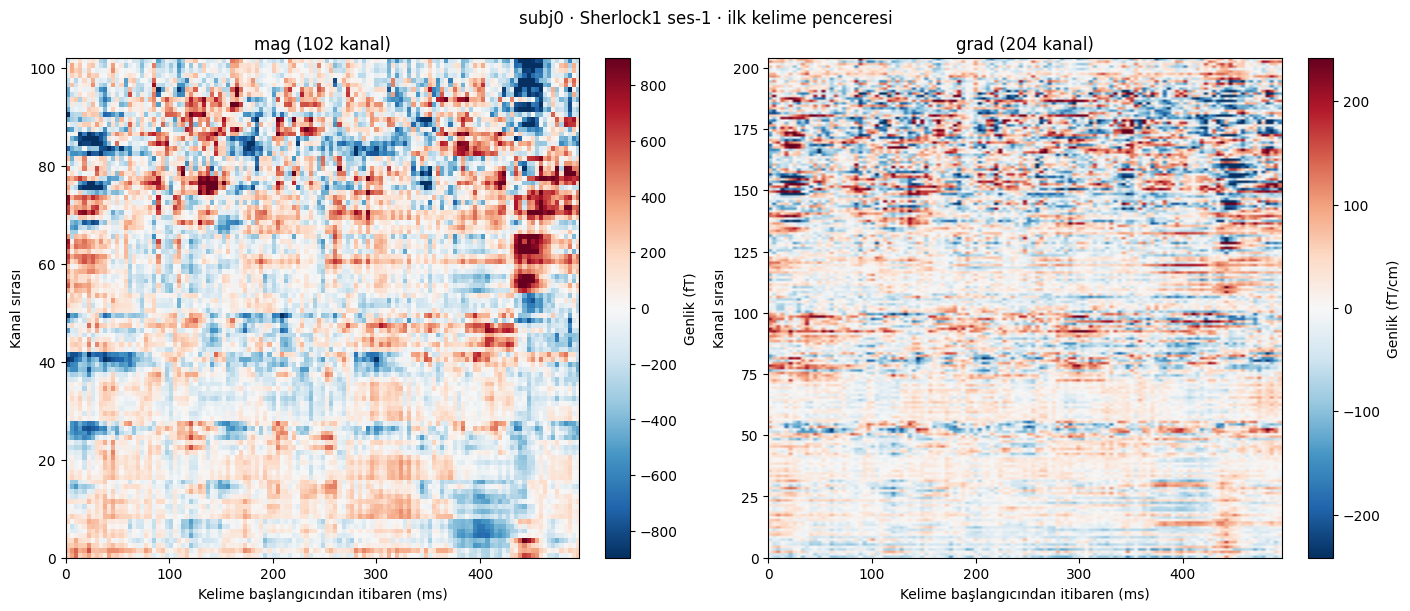

In [13]:
signal = meg_signal.numpy()
time_ms = 1000 * np.arange(signal.shape[1]) / sfreq

fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
for ax, ch_type, unit, scale in zip(axes, ("mag", "grad"), ("fT", "fT/cm"), (1e15, 1e13)):
    x = signal[channel_types == ch_type] * scale
    limit = np.percentile(np.abs(x), 99)
    image = ax.imshow(x, aspect="auto", origin="lower", cmap="RdBu_r", vmin=-limit, vmax=limit,
                      extent=[0, time_ms[-1], 0, x.shape[0]])
    ax.set(title=f"{ch_type} ({x.shape[0]} kanal)", xlabel="Kelime başlangıcından itibaren (ms)",
           ylabel="Kanal sırası")
    fig.colorbar(image, ax=ax, label=f"Genlik ({unit})")
fig.suptitle("subj0 · Sherlock1 ses-1 · ilk kelime penceresi")
plt.show()

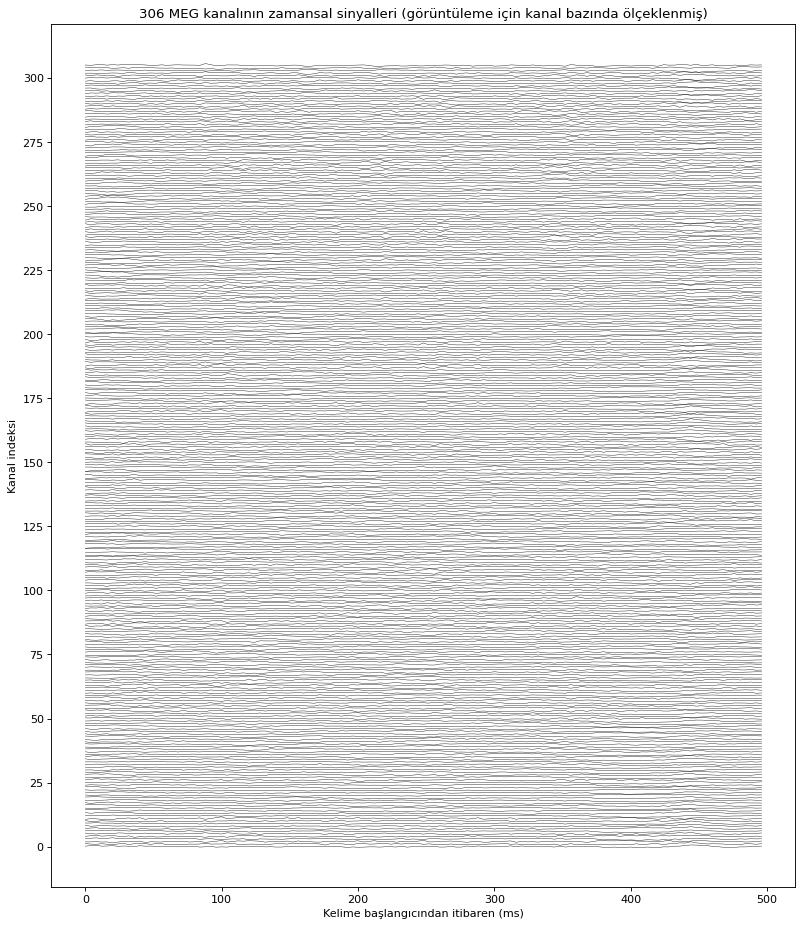

In [14]:
centered = signal - signal.mean(axis=1, keepdims=True)
display_scale = np.where(centered.std(axis=1, keepdims=True) == 0, 1, centered.std(axis=1, keepdims=True))
stacked = centered / display_scale

fig, ax = plt.subplots(figsize=(12, 14), dpi=80)
for channel in range(stacked.shape[0]):
    ax.plot(time_ms, stacked[channel] + 5 * channel, color="black", linewidth=0.35)
ax.set(xlabel="Kelime başlangıcından itibaren (ms)", ylabel="Kanal indeksi",
       title="306 MEG kanalının zamansal sinyalleri (görüntüleme için kanal bazında ölçeklenmiş)")
ax.set_yticks(5 * np.arange(0, N_CHANNELS, 25), np.arange(0, N_CHANNELS, 25))
plt.show()

## Bölüm 5 Veri erişim tablosu ve sınıf dağılımı

Her kayıt için başlık bilgisi (örnekleme frekansı, örnek sayısı, kanal listesi) dosya indirilmeden okunur ve olay dosyasından pencere indeksi oluşturulur. Böylece 226 kaydın tamamı için erişilebilir süre ve 50 kelimelik sözlüğe ait pencere sayısı, ham veri (~85–90 GB) indirilmeden hesaplanır.

Sonuçlar ara dosyalara yazılır; hücre yeniden çalıştırıldığında yalnızca eksik kayıtlar işlenir.



In [15]:
header_path = OUT / "record_headers.csv"
index_path = OUT / "word_events.parquet"

headers = pd.read_csv(header_path).set_index("record").to_dict("index") if header_path.exists() else {}
indices = dict(tuple(pd.read_parquet(index_path).groupby("record"))) if index_path.exists() else {}

todo = records.loc[~records["record"].isin(set(headers) & set(indices))]
for n, rec in enumerate(tqdm(todo.itertuples(), total=len(todo), desc="Kayıtlar"), start=1):
    header = h5_header(rec.meg_repo, rec.meg_path)
    events = read_events(hf_file(rec.tsv_repo, rec.tsv_path))
    headers[rec.record] = header
    indices[rec.record] = build_window_index(events, rec.record, header["sfreq"], header["n_samples"], ONSET_COL)
    if n % 20 == 0 or n == len(todo):
        pd.DataFrame.from_dict(headers, orient="index").rename_axis("record").to_csv(header_path)
        pd.concat(indices.values(), ignore_index=True).to_parquet(index_path)

header_df = pd.DataFrame.from_dict(headers, orient="index").rename_axis("record").reset_index()
windows = (pd.concat(indices.values(), ignore_index=True)
           .merge(records[["record", "subject", "session", "task", "corpus", "partition", "release"]],
                  on="record", validate="many_to_one"))
assert set(header_df["record"]) == set(records["record"])
print("Kayıt:", len(header_df), "· kelime olayı:", len(windows))
print("Başlık okuma yolu (bu çalıştırmada):", dict(HEADER_SOURCE))

Kayıtlar: 0it [00:00, ?it/s]

Kayıt: 226 · kelime olayı: 1004288
Başlık okuma yolu (bu çalıştırmada): {}


### Olay dosyalarının bütünlüğü

Tek bir ses kaydında kelimeler üst üste binemez: olay dosyasındaki sırayla (uyaranın gerçek sırası) okunduğunda kelime başlangıç zamanları hiç geriye gitmemelidir. Zaman geriye gidiyorsa, o kayıtta bazı kelimelerin zaman damgaları yanlıştır ve bu kelimelerden kesilen pencereler MEG sinyaliyle doğru hizalanmaz.

Aşağıdaki hücre her kayıt için kelimeleri dosya sırasıyla okur, geriye giden ve aynı kalan başlangıç zamanlarını sayar ve kelime dizisini Bölüm 7'deki uyaran testleri için saklar. Olay dosyaları önceki adımda indirildiği için bu hücre hızlı çalışır.

Sorunun ölçeğine göre önceden tanımlı iki kural uygulanır:

* **Seyrek çakışma** (kayıtta en çok `MAX_BACKWARD_STEPS` geri adım): Geri adımın kapsadığı zaman aralığı belirsiz kabul edilir. Penceresi bu aralıkla kesişen kelimeler kullanılmaz (`timing_ok = False`); kaydın geri kalanı korunur.
* **Sistematik çakışma** (daha fazla geri adım): Kayıttaki zaman damgalarına güvenilemez; katılımcı Bölüm 6'da gerekçesiyle dışlanır. Bölüm 7'deki T8 testi bu kuralın uygulandığını denetler.

In [16]:
integrity_rows, sequences, onset_tables = [], {}, {}
for rec in tqdm(list(records.itertuples()), desc="Olay dosyaları"):
    words = file_order_words(read_events(hf_file(rec.tsv_repo, rec.tsv_path)), ONSET_COL)
    steps = np.diff(words["onset"].to_numpy())
    sequences[rec.record] = words["word"].tolist()
    onset_tables[rec.record] = words
    integrity_rows.append({
        "record": rec.record, "subject": rec.subject, "session": rec.session, "task": rec.task,
        "n_words": len(words), "n_nan_onsets": int(words["onset"].isna().sum()),
        "n_backward_steps": int((steps < 0).sum()), "n_equal_onsets": int((steps == 0).sum()),
        "max_backward_step_s": float(-steps[steps < 0].min()) if (steps < 0).any() else 0.0,
    })

event_integrity = pd.DataFrame(integrity_rows)
event_integrity.to_csv(OUT / "event_integrity.csv", index=False)
(OUT / "word_sequences.json").write_text(json.dumps(sequences))

problem_records = event_integrity.loc[event_integrity["n_backward_steps"].gt(0) | event_integrity["n_nan_onsets"].gt(0)]
print("Zaman damgası sorunlu kayıt:", len(problem_records), "/", len(event_integrity))
display(problem_records)
# Seyrek çakışmalar: belirsiz zaman aralıklarını işaretle
MAX_BACKWARD_STEPS = 2
conflict_rows = []
for record_id in problem_records["record"]:
    onsets = onset_tables[record_id]["onset"].to_numpy()
    for i in np.flatnonzero(np.diff(onsets) < 0):
        conflict_rows.append({"record": record_id, "span_start_s": onsets[i + 1],
                              "span_end_s": onsets[i]})
timing_conflicts = pd.DataFrame(conflict_rows, columns=["record", "span_start_s", "span_end_s"])
timing_conflicts.to_csv(OUT / "timing_conflicts.csv", index=False)

windows["timing_ok"] = True
for conflict in timing_conflicts.itertuples():
    in_span = (windows["record"].eq(conflict.record)
               & windows["onset"].le(conflict.span_end_s)
               & (windows["onset"] + WINDOW_SEC).gt(conflict.span_start_s))
    windows.loc[in_span, "timing_ok"] = False

minor = problem_records.loc[problem_records["n_backward_steps"].le(MAX_BACKWARD_STEPS)
                            & problem_records["n_nan_onsets"].eq(0), "record"]
dropped = windows.loc[windows["record"].isin(minor) & ~windows["timing_ok"]]
print(f"Seyrek çakışmalı kayıt: {len(minor)} · kullanılmayan kelime: {len(dropped)} "
      f"(50 sınıflık pencere: {int((dropped['fits'] & dropped['in_vocab']).sum())})")
if len(minor):
    log_deviation("seyrek_zaman_cakismasi", "2.1 (veri keşfi), 2.2",
                  "Eksik veya bozuk kayıtlar veri keşfinde belirlenir",
                  f"{len(minor)} kayıtta olay zamanlarının çakıştığı aralıklara denk gelen {len(dropped)} kelime "
                  "kullanılmadı; kayıtların geri kalanı korundu",
                  "Bu kayıtlarda kelime başlangıç zamanı yalnızca bir noktada geriye gidiyor")

Olay dosyaları:   0%|          | 0/226 [00:00<?, ?it/s]

Zaman damgası sorunlu kayıt: 9 / 226


,record,subject,session,task,n_words,n_nan_onsets,n_backward_steps,n_equal_onsets,max_backward_step_s
27,sub-0_ses-12_task-Sherlock2_run-1,0,12,Sherlock2,10431,0,1,0,2.430
40,sub-0_ses-1_task-Sherlock4_run-1,0,1,Sherlock4,9716,0,1,0,0.040
77,sub-0_ses-11_task-Sherlock6_run-1,0,11,Sherlock6,8983,0,1,0,0.120
102,sub-0_ses-8_task-Sherlock8_run-1,0,8,Sherlock8,7767,0,1,0,0.050
138,sub-0_ses-7_task-TheMoth_run-1,0,7,TheMoth,3454,0,1,0,0.170
140,sub-0_ses-9_task-TheMoth_run-1,0,9,TheMoth,2034,0,1,0,0.920
145,sub-0_ses-14_task-TheMoth_run-1,0,14,TheMoth,1933,0,1,0,0.500
218,sub-29_ses-11_task-Sherlock1_run-1,29,11,Sherlock1,3421,0,60,0,12.528
219,sub-29_ses-12_task-Sherlock1_run-1,29,12,Sherlock1,3570,0,62,0,9.576


Seyrek çakışmalı kayıt: 7 · kullanılmayan kelime: 28 (50 sınıflık pencere: 6)


Sorunlu bir hedef katılımcı bulunursa, aşağıdaki şekil o katılımcının kelime başlangıçlarını subj0'ın aynı oturumdaki başlangıçlarıyla kelime kelime karşılaştırır. Aynı ses dosyasını dinleyen iki kişide bu fark (sabit bir kayma dışında) düz bir çizgi olmalıdır; karşılaştırma için sorunsuz bir değerlendirme katılımcısı da çizilir. Kayıtların sonundaki kapanış duyurusu ("end of book two chapter four") bazı olay dosyalarında yer almadığı için karşılaştırma ortak uzunlukta yapılır.

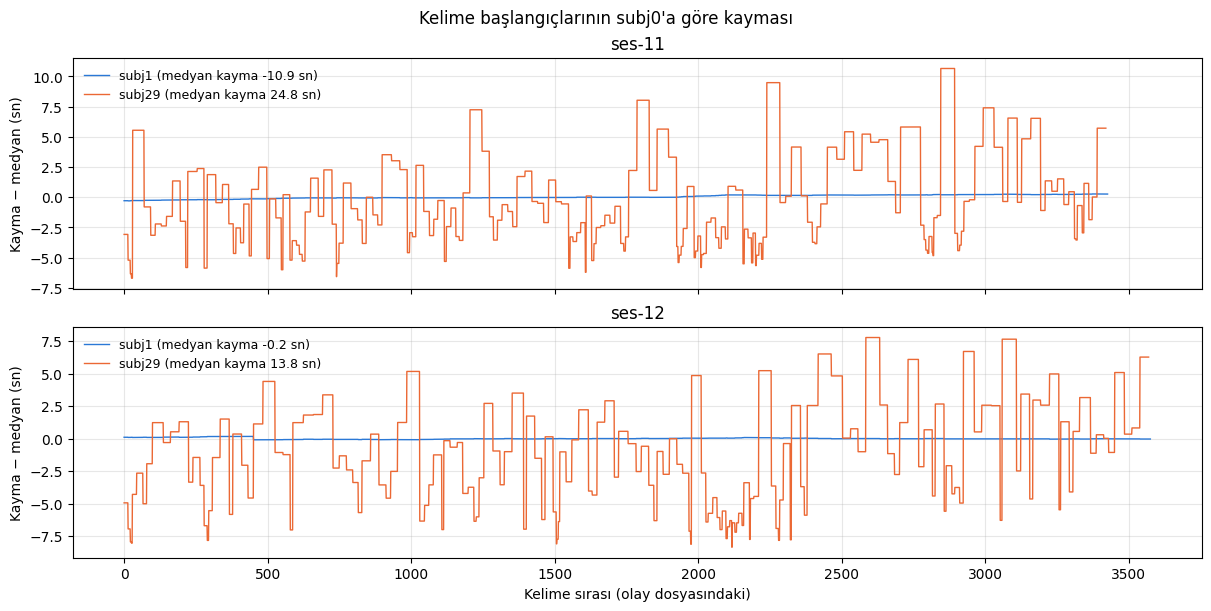

In [17]:
problem_targets = sorted(set(problem_records.loc[problem_records["subject"].ge(1), "subject"]))
if problem_targets:
    control = int(records.loc[records["subject"].ge(1) & records["release"].eq("standart"), "subject"].min())
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout="constrained")
    for ax, session in zip(axes, (11, 12)):
        reference = onset_tables[record_of(0, "Sherlock1", session)]
        for subj, color in [(control, "#2a78d6")] + [(s, "#eb6834") for s in problem_targets]:
            current = onset_tables[record_of(subj, "Sherlock1", session)]
            n = min(len(reference), len(current))
            assert (reference["word"].to_numpy()[:n] == current["word"].to_numpy()[:n]).all(), \
                f"subj{subj} ses-{session}: dosya sırasındaki kelimeler subj0'dan farklı"
            lag = current["onset"].to_numpy()[:n] - reference["onset"].to_numpy()[:n]
            ax.plot(lag - np.median(lag), lw=1, color=color, label=f"subj{subj} (medyan kayma {np.median(lag):.1f} sn)")
        ax.set(ylabel="Kayma − medyan (sn)", title=f"ses-{session}")
        ax.grid(alpha=0.3)
        ax.legend(frameon=False, fontsize=9)
    axes[-1].set_xlabel("Kelime sırası (olay dosyasındaki)")
    fig.suptitle("Kelime başlangıçlarının subj0'a göre kayması")
    fig.savefig(OUT / "event_timing_drift.png", dpi=200, bbox_inches="tight")
    plt.show()

Kanal düzeni ve örnekleme frekansı tüm kayıtlarda pilot kayıtla aynı olmalıdır (Öneri 2.2/3, R5). Uyuşmazlık olursa ortak kanal kümesi uygulanması gerekir; bu durumda aşağıdaki hücre uyuşmayan kayıtları listeler ve durur.

In [18]:
mismatch = header_df.loc[
    header_df["channel_names"].ne(pilot_header["channel_names"])
    | header_df["channel_types"].ne(pilot_header["channel_types"])
    | header_df["sfreq"].ne(EXPECTED_SFREQ)
    | header_df["n_channels"].ne(N_CHANNELS)
]
print("Kanal düzeni veya örnekleme frekansı farklı kayıt:", len(mismatch))
assert mismatch.empty, mismatch[["record", "sfreq", "n_channels"]]

Kanal düzeni veya örnekleme frekansı farklı kayıt: 0


In [19]:
usable = windows.loc[windows["fits"] & windows["in_vocab"] & windows["timing_ok"]]
access = (
    header_df.assign(minutes=lambda d: d["n_samples"] / d["sfreq"] / 60)[["record", "minutes"]]
    .merge(records[["record", "subject", "session", "task", "partition", "release"]], on="record")
    .merge(windows.groupby("record").agg(word_events=("fits", "size"), fitting_words=("fits", "sum")),
           on="record", how="left")
    .merge(usable.groupby("record").agg(windows_50=("label", "size"), classes_50=("label", "nunique")),
           on="record", how="left")
    .fillna({"word_events": 0, "fitting_words": 0, "windows_50": 0, "classes_50": 0})
    .astype({"word_events": int, "fitting_words": int, "windows_50": int, "classes_50": int})
    .sort_values(["subject", "task", "session"])
)
access.to_csv(OUT / "data_access.csv", index=False)

print("subj0 — standart bölümlere göre")
display(access.loc[access["subject"].eq(0)]
        .groupby("partition")
        .agg(kayıt=("record", "size"), saat=("minutes", lambda m: m.sum() / 60),
             pencere_50=("windows_50", "sum"))
        .round(2))

print("subj1–32 — katılımcı × oturum (dakika / 50 sınıf penceresi / görülen sınıf)")
target_access = access.loc[access["subject"].ge(1)].pivot(
    index="subject", columns="session", values=["release", "minutes", "windows_50", "classes_50"])
display(target_access.round(2))

subj0 — standart bölümlere göre


,kayıt,saat,pencere_50
partition,,,
test,3,0.98,2681
train,156,84.62,307329
validation,3,0.97,3052


subj1–32 — katılımcı × oturum (dakika / 50 sınıf penceresi / görülen sınıf)


release                  minutes            windows_50        \
session            11            12         11         12         11    12   
subject                                                                      
1            standart      standart      23.05  24.033333       1308  1364   
2            standart      standart  23.666667  24.533333       1308  1364   
3            standart      standart       23.8  25.033333       1308  1364   
4            standart      standart      23.65      25.05       1308  1364   
5            standart      standart  23.983333  24.983333       1308  1364   
6            standart      standart  23.066667       24.8       1308  1364   
7            standart      standart  26.316667  25.116667       1308  1364   
8            standart      standart  23.633333  24.933333       1308  1364   
9            standart      standart      24.65       24.9       1308  1364   
10           standart      standart  23.716667      25.05       1308  1364   
11           standart      standart  23.083333  24.783333       1308  1364   
12           standart      standart      23.15  24.333333       1308  1364   
13          firsthalf     firsthalf     11.775      12.35        678   697   
14          firsthalf     firsthalf  11.983333       12.7        682   697   
15          firsthalf     firsthalf     11.675      12.35        669   691   
16          firsthalf     firsthalf  11.966667  12.491667        671   705   
17          firsthalf     firsthalf       11.5  12.091667        665   686   
18          firsthalf     firsthalf     11.675  12.316667        671   698   
19          firsthalf     firsthalf  11.566667  12.391667        665   673   
20          firsthalf     firsthalf      12.05  12.466667        700   714   
21          firsthalf     firsthalf  11.541667     12.375        667   699   
22          firsthalf     firsthalf  11.608333     12.425        673   695   
23       firstquarter  firstquarter      5.775   6.129133        319   331   
24       firstquarter  firstquarter   5.833333     6.1208        306   331   
25       firstquarter  firstquarter      5.725     6.0708        315   331   
26       firstquarter  firstquarter   6.087467   6.233333        336   324   
27       firstquarter  firstquarter   5.779133   6.162467        323   331   
28       firstquarter  firstquarter   5.804133   6.091667        319   326   
29       firstquarter  firstquarter   5.891667   6.087467        181   252   
30       firstquarter  firstquarter      5.875     6.2958        316   324   
31       firstquarter  firstquarter       5.75   6.154133        315   324   
32       firstquarter  firstquarter        5.9   6.391667        319   331   

        classes_50      
session         11  12  
subject                 
1               47  45  
2               47  45  
3               47  45  
4               47  45  
5               47  45  
6               47  45  
7               47  45  
8               47  45  
9               47  45  
10              47  45  
11              47  45  
12              47  45  
13              44  37  
14              44  37  
15              44  37  
16              44  37  
17              44  37  
18              44  37  
19              44  36  
20              44  37  
21              44  37  
22              44  37  
23              41  35  
24              41  35  
25              41  35  
26              41  35  
27              41  35  
28              41  35  
29              36  33  
30              41  35  
31              41  35  
32              41  35

Yukarıdaki tablo, Öneri Bölüm 2.1'de İP-1'in ilk çıktısı olarak tanımlanan **veri erişim tablosudur**. Öneri, subj0 için yaklaşık 78,6 saat kaynak eğitim verisi ve 50 kelimelik sözlüğe ait yaklaşık 300 bin pencere öngörmüştür; gerçek değerler buradaki ölçümlerdir ve Bölüm 9'daki hesaplama planına bu değerler girer.

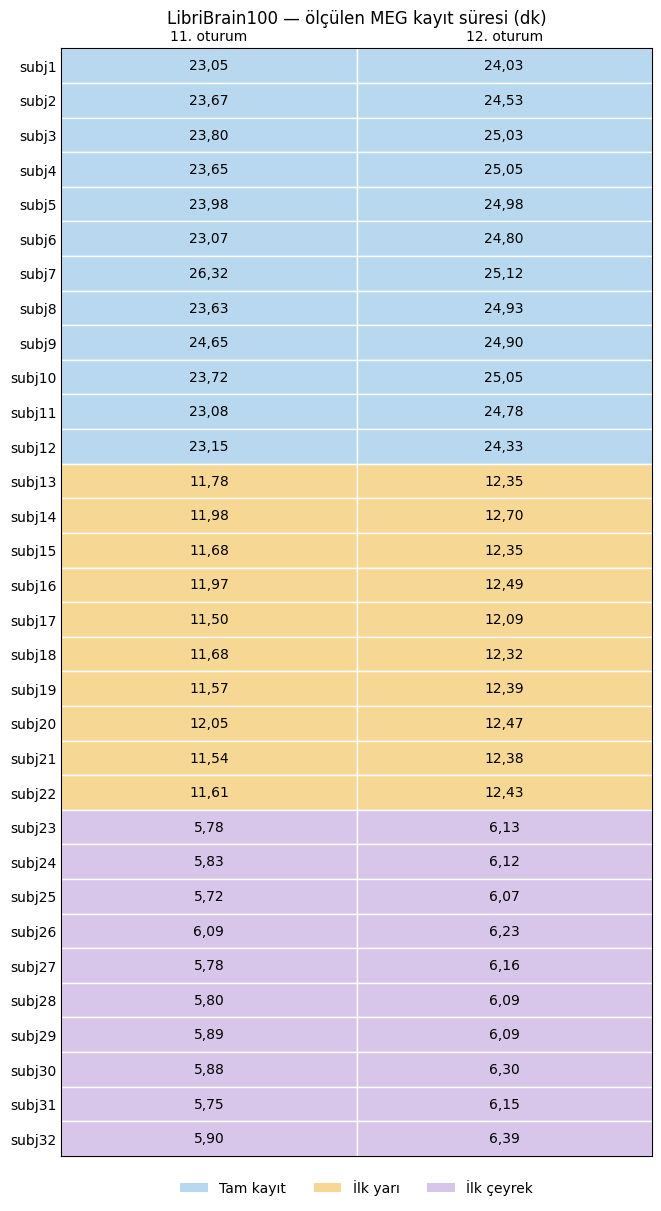

In [20]:
# Katılımcı ve oturum bazında ölçülen kayıt süresi
participants = TARGET_SUBJECTS
release_colors = {"standart": "#B8D8F0", "firsthalf": "#F7D794", "firstquarter": "#D8C5EA"}
release_labels = {"standart": "Tam kayıt", "firsthalf": "İlk yarı", "firstquarter": "İlk çeyrek"}
minutes_tbl = access.loc[access["subject"].ge(1)].pivot(index="subject", columns="session", values="minutes")
release_tbl = access.loc[access["subject"].ge(1)].pivot(index="subject", columns="session", values="release")

fig, ax = plt.subplots(figsize=(6.5, 12), layout="constrained")
for row, subject in enumerate(participants):
    for col, session in enumerate((11, 12)):
        ax.add_patch(Rectangle((col, row), 1, 1, edgecolor="white",
                               facecolor=release_colors.get(release_tbl.at[subject, session], "#EEEEEE")))
        ax.text(col + 0.5, row + 0.5, f"{minutes_tbl.at[subject, session]:.2f}".replace(".", ","),
                ha="center", va="center")
ax.set_xlim(0, 2)
ax.set_ylim(len(participants), 0)
ax.set_xticks([0.5, 1.5], ["11. oturum", "12. oturum"])
ax.xaxis.tick_top()
ax.set_yticks([r + 0.5 for r in range(len(participants))], [f"subj{s}" for s in participants])
ax.tick_params(length=0)
ax.set_title("LibriBrain100 — ölçülen MEG kayıt süresi (dk)", pad=18)
ax.legend(handles=[Patch(facecolor=c, label=release_labels[k]) for k, c in release_colors.items()],
          loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=3, frameon=False)
plt.show()

### 50 sınıfın frekans dağılımı

Sınıf frekansları kaynak eğitim, kaynak doğrulama/test ve hedef katılımcıların tam oturumları için ayrı ayrı hesaplanır. Hedef katılımcıların tümü aynı uyaranı dinlediği için tam kayıtlarda sınıf sayıları katılımcılar arasında aynıdır; bu nedenle hedef sütunlarında tek bir tam kayıt gösterilir.

Öneri Bölüm 2.5'e göre test kümesinde örneği bulunmayan sınıflar BAcc@10 ortalamasına katılmaz ve sayıları her katılımcı için raporlanır; bu sayılar ikinci tabloda verilir.

,word,subj0_train,subj0_validation,subj0_test,subj1_ses11,subj1_ses12
label,,,,,,
0,is,7679,46,41,13,8
1,the,40252,487,403,264,213
2,a,17990,184,173,59,93
3,to,18191,186,155,86,91
4,it,11421,63,52,32,34
5,i,18828,193,90,15,5
6,not,4031,27,26,12,10
7,was,10922,127,101,53,70
8,we,4769,36,40,14,4


subject,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,...,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32
classes_missing_in_test,5,5,5,5,5,5,5,5,5,5,5,5,13,13,13,...,13,14,13,13,13,15,15,15,15,15,15,17,15,15,15


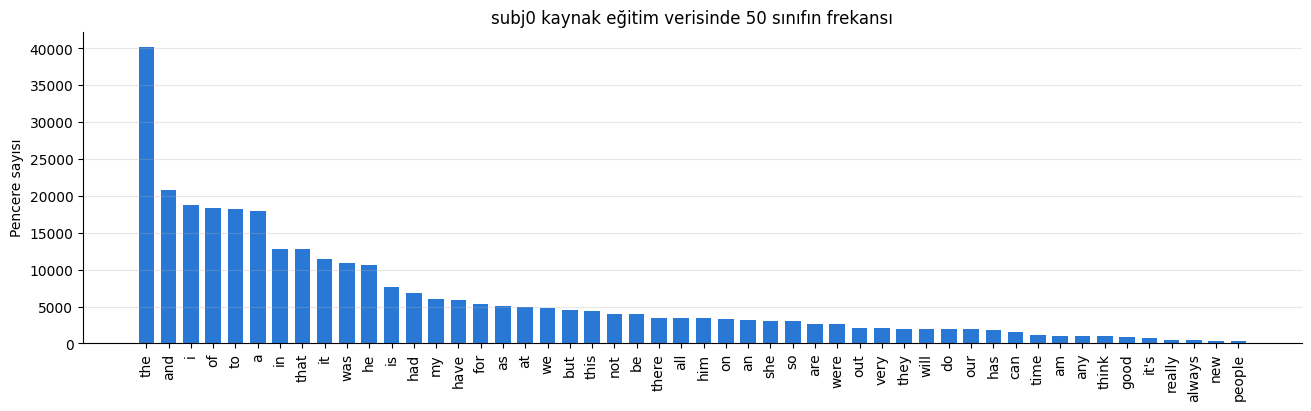

In [21]:
def class_counts(frame):
    return frame["label"].value_counts().reindex(range(50), fill_value=0)

reference_target = int(access.loc[access["subject"].ge(1) & access["release"].eq("standart"), "subject"].min())
freq = pd.DataFrame({
    "word": VOCAB,
    "subj0_train": class_counts(usable.loc[usable["subject"].eq(0) & usable["partition"].eq("train")]),
    "subj0_validation": class_counts(usable.loc[usable["subject"].eq(0) & usable["partition"].eq("validation")]),
    "subj0_test": class_counts(usable.loc[usable["subject"].eq(0) & usable["partition"].eq("test")]),
    f"subj{reference_target}_ses11": class_counts(usable.loc[usable["subject"].eq(reference_target) & usable["session"].eq(11)]),
    f"subj{reference_target}_ses12": class_counts(usable.loc[usable["subject"].eq(reference_target) & usable["session"].eq(12)]),
}).rename_axis("label")
freq.to_csv(OUT / "class_frequencies.csv")
display(freq)

missing_in_test = (usable.loc[usable["subject"].ge(1) & usable["session"].eq(12)]
                   .groupby("subject")["label"].nunique().rsub(50)
                   .reindex(TARGET_SUBJECTS, fill_value=50).rename("classes_missing_in_test"))
display(missing_in_test.to_frame().T)

ordered = freq.sort_values("subj0_train", ascending=False)
fig, ax = plt.subplots(figsize=(13, 4), layout="constrained")
ax.bar(ordered["word"], ordered["subj0_train"], color="#2a78d6", width=0.7)
ax.set(ylabel="Pencere sayısı", title="subj0 kaynak eğitim verisinde 50 sınıfın frekansı")
ax.tick_params(axis="x", rotation=90)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## Bölüm 6 Senaryo kararı, katılımcı rolleri ve uyarlama alt kümeleri

### Senaryo kararı

Öneri Bölüm 2.1'e göre birincil tasarım, 32 katılımcının 11. ve 12. oturumlarının tam olarak erişilebilir olmasına dayanır; proje başladığında yalnızca kademeli sürüm erişilebilirse **R2 B planı** uygulanır. Karar Bölüm 3'teki sürüm tablosuna göre otomatik verilir ve sabitlenen veri commit'iyle birlikte kaydedilir.

| | Birincil tasarım | R2 B planı |
|---|---|---|
| Değerlendirme | 32 katılımcıdan 8 geliştirme dışındaki 24 kişi | Verisi tam yayımlanan 12 katılımcı |
| Geliştirme | Sabit tohumla seçilen 8 katılımcı | ~20 dk grubundan sabit tohumla seçilen 8 katılımcı |
| Betimsel | — | ~10 dk grubu (yalnız A1) ve ~20 dk grubunda geliştirmeye seçilmeyen katılımcılar (A1–A2) |

Geliştirme katılımcıları hiçbir hipotez testine girmez. Değerlendirme katılımcılarında ayar yapılmaz, erken durdurma kullanılmaz ve 12. oturum yalnızca nihai test için kullanılır.

### Dışlanan katılımcılar

Olay dosyasındaki kelime zamanları tutarsız olan katılımcılar (Bölüm 5, olay dosyalarının bütünlüğü) rol atamasından önce dışlanır. Dışlama listesi elle ve gerekçesiyle tutulur; Bölüm 7'deki T8 testi, zaman damgası sorunlu her kaydın bu listede olduğunu denetler.

In [22]:
EXCLUDED_SUBJECTS = {
    29: "Olay dosyalarında (ses-11 ve ses-12) kelime başlangıç zamanları dosya sırasında geriye gidiyor; "
        "cümleler zamanda iç içe geçiyor. Pencereler MEG ile güvenilir biçimde hizalanamaz.",
}
for subj, reason in EXCLUDED_SUBJECTS.items():
    log_deviation(f"dislama_subj{subj}", "R2",
                  "~10 dakikalık gruptaki katılımcılar A1 düzeyinde betimsel raporlanır",
                  f"subj{subj} tüm analizlerden çıkarıldı", reason)

target_release = access.loc[access["subject"].ge(1)].pivot(index="subject", columns="session", values="release")
target_release = target_release.drop(index=list(EXCLUDED_SUBJECTS))
full = sorted(target_release.index[(target_release[11] == "standart") & (target_release[12] == "standart")])
half = sorted(target_release.index[target_release[11] == "firsthalf"])
quarter = sorted(target_release.index[target_release[11] == "firstquarter"])

rng = np.random.default_rng(SEED)
if len(full) == 32:
    PLAN = "birincil"
    development = sorted(int(s) for s in rng.choice(full, 8, replace=False))
    evaluation = [s for s in full if s not in development]
    descriptive_a1, descriptive_a2 = [], []
else:
    PLAN = "R2"
    development = sorted(int(s) for s in rng.choice(half, 8, replace=False))
    evaluation = list(full)
    descriptive_a1 = list(quarter)                                  # yalnız A1, betimsel
    descriptive_a2 = [s for s in half if s not in development]      # A1–A2, betimsel
    log_deviation(
        "R2_secilmeyen", "R2",
        "~20 dakikalık gruptan sabit tohumla 8 geliştirme katılımcısı seçilir",
        f"Seçilmeyen katılımcılar ({', '.join(f'subj{s}' for s in descriptive_a2)}) A1–A2 düzeyinde betimsel raporlanır",
        "Öneri bu katılımcılara rol tanımlamamaktadır",
    )
    log_deviation(
        "R2_gelistirme_A3", "2.1, R2",
        "Geliştirme katılımcılarında uyarlama, değerlendirmedekiyle aynı A1–A3 alt kümeleriyle yapılır",
        "Geliştirme katılımcılarında ayarlar A1 ve A2 düzeyinde seçilir; A3 için A2'de seçilen ayarlar kullanılır",
        "R2'de geliştirme katılımcılarının 11. oturumu yalnızca ilk yarıdır (~12 dk); A3 düzeyine ulaşılamaz",
    )

ROLE_OF = ({s: "evaluation" for s in evaluation} | {s: "development" for s in development}
           | {s: "descriptive_a1" for s in descriptive_a1} | {s: "descriptive_a2" for s in descriptive_a2}
           | {s: "excluded" for s in EXCLUDED_SUBJECTS})
assert sorted(ROLE_OF) == TARGET_SUBJECTS, "Her hedef katılımcının tam olarak bir rolü olmalı"

roles = {
    "plan": PLAN, "seed": SEED, "hf_revision": HF_REVISION,
    "evaluation": evaluation, "development": development,
    "descriptive_a1": descriptive_a1, "descriptive_a2": descriptive_a2,
    "excluded": {str(s): r for s, r in EXCLUDED_SUBJECTS.items()},
}
(OUT / "participant_roles.json").write_text(json.dumps(roles, indent=2))
print("Uygulanan plan:", PLAN)
display(pd.Series({k: v for k, v in roles.items() if isinstance(v, list)}
                  | {"excluded": sorted(EXCLUDED_SUBJECTS)}).to_frame("katılımcılar"))

Uygulanan plan: R2


,katılımcılar
evaluation,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]"
development,"[13, 14, 15, 16, 17, 19, 20, 22]"
descriptive_a1,"[23, 24, 25, 26, 27, 28, 30, 31, 32]"
descriptive_a2,"[18, 21]"
excluded,[29]


### Veri bölümlerinin rolleri

Her kaydın projedeki rolü aşağıdaki gibi tanımlanır. PNPL'nin `validation` / `test` adlarıyla karışmaması için kodda bu rol adları kullanılır.

| Katılımcı grubu | 11. oturum | 12. oturum |
|---|---|---|
| subj0 | `src_validation` (Sherlock1 ses-11) | `src_test` (Sherlock1 ses-12) |
| Değerlendirme | `eval_adapt` (A1 ⊂ A2 ⊂ A3) | `eval_test` (yalnız nihai test) |
| Geliştirme | `dev_adapt` (A1 ⊂ A2) | `dev_select` (ayar seçimi; doğrulama işlevi) |
| Betimsel | `desc_adapt` | `desc_test` (yalnız betimsel rapor, hipotez testine girmez) |
| Dışlanan | `excluded` | `excluded` (hiçbir analizde ve arşivde kullanılmaz) |

subj0'ın diğer 156 kaydı `src_train`; MOCHA-TIMIT ve TheMoth doğrulama/test kayıtları da PNPL bölümlerine göre `src_validation` / `src_test` olur.

Geliştirme katılımcılarının 12. oturumu ayar seçiminde kullanılır. Bu, değerlendirme katılımcılarının test verisine dokunmadığı için kişiler arası bir sızıntı değildir; ancak tüm katılımcılar aynı uyaranı dinlediğinden olası uyaran düzeyindeki yanlılık sonuç raporunda sınırlılık olarak belirtilir.

In [23]:
SPLIT_ROLE = {
    ("evaluation", 11): "eval_adapt", ("evaluation", 12): "eval_test",
    ("development", 11): "dev_adapt", ("development", 12): "dev_select",
    ("descriptive_a1", 11): "desc_adapt", ("descriptive_a1", 12): "desc_test",
    ("descriptive_a2", 11): "desc_adapt", ("descriptive_a2", 12): "desc_test",
    ("excluded", 11): "excluded", ("excluded", 12): "excluded",
}

def split_role(row):
    if row["subject"] == 0:
        return f"src_{row['partition']}"
    return SPLIT_ROLE[(ROLE_OF[row["subject"]], row["session"])]

records["split_role"] = records.apply(split_role, axis=1)
records["participant_role"] = records["subject"].map(ROLE_OF).fillna("source")
windows = windows.drop(columns=["split_role", "participant_role"], errors="ignore").merge(
    records[["record", "split_role", "participant_role"]], on="record", validate="many_to_one")
display(records.groupby(["participant_role", "split_role"]).size().rename("Kayıt").to_frame())

Kayıt
participant_role split_role           
descriptive_a1   desc_adapt          9
                 desc_test           9
descriptive_a2   desc_adapt          2
                 desc_test           2
development      dev_adapt           8
                 dev_select          8
evaluation       eval_adapt         12
                 eval_test          12
excluded         excluded            2
source           src_test            3
                 src_train         156
                 src_validation      3

### Uyarlama alt kümeleri (A1–A3)

Uyarlama verisi 11. oturumdan, kaydın başından itibaren iç içe alt kümeler olarak alınır (Öneri 2.4):

* **A1:** kaydın içine tam sığan ilk kelimeden itibaren 5 dakika
* **A2:** aynı noktadan itibaren 10 dakika
* **A3:** 11. oturumun tamamı (yalnız değerlendirme katılımcıları)

Bir pencere, ancak tamamı ilgili süre sınırının içinde kalıyorsa alt kümeye girer. Kayıt bir düzeyin süresine ulaşmıyorsa o düzey o katılımcı için tanımlanmaz. Raporlanacak gerçek dakika ve pencere sayıları aşağıdaki tabloya yazılır.

In [24]:
LEVELS_BY_ROLE = {"evaluation": ("A1", "A2", "A3"), "development": ("A1", "A2"),
                  "descriptive_a2": ("A1", "A2"), "descriptive_a1": ("A1",)}
LEVEL_MINUTES = {"A1": 5, "A2": 10, "A3": None}         # None = oturumun tamamı


def adaptation_masks(record_windows, n_samples, sfreq, levels):
    fitting = record_windows.loc[record_windows["fits"]]
    first_onset = fitting["onset"].min()
    end_sec = n_samples / sfreq
    masks, minutes = {}, {}
    for level in levels:
        cutoff = end_sec if LEVEL_MINUTES[level] is None else first_onset + 60 * LEVEL_MINUTES[level]
        if cutoff > end_sec + 1e-9:
            continue
        masks[level] = (record_windows["fits"] & record_windows["in_vocab"] & record_windows["timing_ok"]
                        & (record_windows["stop"] / sfreq <= cutoff + 1e-9))
        minutes[level] = (cutoff - first_onset) / 60
    return masks, minutes


for level in LEVEL_MINUTES:
    windows[f"in_{level}"] = False
windows["in_A_all"] = False                               # 11. oturumda erişilebilen uyarlama verisinin tamamı

subset_rows = []
adapt_records = records.loc[records["split_role"].isin(["eval_adapt", "dev_adapt", "desc_adapt"])]
for rec in adapt_records.itertuples():
    selector = windows["record"].eq(rec.record)
    header = headers[rec.record]
    masks, minutes = adaptation_masks(windows.loc[selector], header["n_samples"], header["sfreq"],
                                      LEVELS_BY_ROLE[rec.participant_role])
    row = {"subject": rec.subject, "role": rec.participant_role}
    usable_all = (windows.loc[selector, "fits"] & windows.loc[selector, "in_vocab"]
                  & windows.loc[selector, "timing_ok"])
    windows.loc[selector, "in_A_all"] = usable_all.to_numpy()
    first_onset = windows.loc[selector & windows["fits"], "onset"].min()
    row["all_min"] = round((header["n_samples"] / header["sfreq"] - first_onset) / 60, 2)
    row["all_windows"] = int(usable_all.sum())
    for level in LEVEL_MINUTES:
        if level in masks:
            windows.loc[selector, f"in_{level}"] = masks[level].to_numpy()
            row[f"{level}_min"] = round(minutes[level], 2)
            row[f"{level}_windows"] = int(masks[level].sum())
            row[f"{level}_classes"] = int(windows.loc[selector & windows[f"in_{level}"], "label"].nunique())
    subset_rows.append(row)

adaptation_table = pd.DataFrame(subset_rows).sort_values("subject").reset_index(drop=True)
adaptation_table.to_csv(OUT / "adaptation_subsets.csv", index=False)
display(adaptation_table)

short_a1 = adaptation_table.loc[adaptation_table["A1_min"].isna(), "subject"].tolist()
if short_a1:
    log_deviation("A1_eksik", "R2",
                  "~10 dakikalık gruptaki katılımcılar A1 düzeyinde betimsel raporlanır",
                  f"{', '.join(f'subj{s}' for s in short_a1)} için 5 dakikalık A1 alt kümesi oluşturulamadı; "
                  "bu katılımcılar betimsel raporda erişilebilir sürenin tamamıyla (manifestte `in_A_all`) ve gerçek dakikasıyla (`all_min`) verilir",
                  "Kayıt, ilk kelimeden itibaren 5 dakikaya ulaşmamaktadır")

,subject,role,all_min,all_windows,A1_min,A1_windows,A1_classes,A2_min,A2_windows,A2_classes,A3_min,A3_windows,A3_classes
0,1,evaluation,22.52,1308,5.0,307.0,41.0,10.0,604.0,43.0,22.52,1308.0,47.0
1,2,evaluation,23.04,1308,5.0,307.0,41.0,10.0,604.0,43.0,23.04,1308.0,47.0
2,3,evaluation,23.29,1308,5.0,307.0,41.0,10.0,604.0,43.0,23.29,1308.0,47.0
3,4,evaluation,23.05,1308,5.0,307.0,41.0,10.0,603.0,43.0,23.05,1308.0,47.0
4,5,evaluation,23.31,1308,5.0,307.0,41.0,10.0,604.0,43.0,23.31,1308.0,47.0
5,6,evaluation,22.36,1308,5.0,307.0,41.0,10.0,603.0,43.0,22.36,1308.0,47.0
6,7,evaluation,25.59,1308,5.0,307.0,41.0,10.0,603.0,43.0,25.59,1308.0,47.0
7,8,evaluation,23.20,1308,5.0,307.0,41.0,10.0,604.0,43.0,23.20,1308.0,47.0
8,9,evaluation,24.07,1308,5.0,307.0,41.0,10.0,604.0,43.0,24.07,1308.0,47.0
9,10,evaluation,23.18,1308,5.0,307.0,41.0,10.0,604.0,43.0,23.18,1308.0,47.0


### Rol haritası

Aşağıdaki şekil, her hedef katılımcının iki oturumunun projedeki rolünü gösterir. Hücrelerdeki süreler ölçülen kayıt süreleridir.

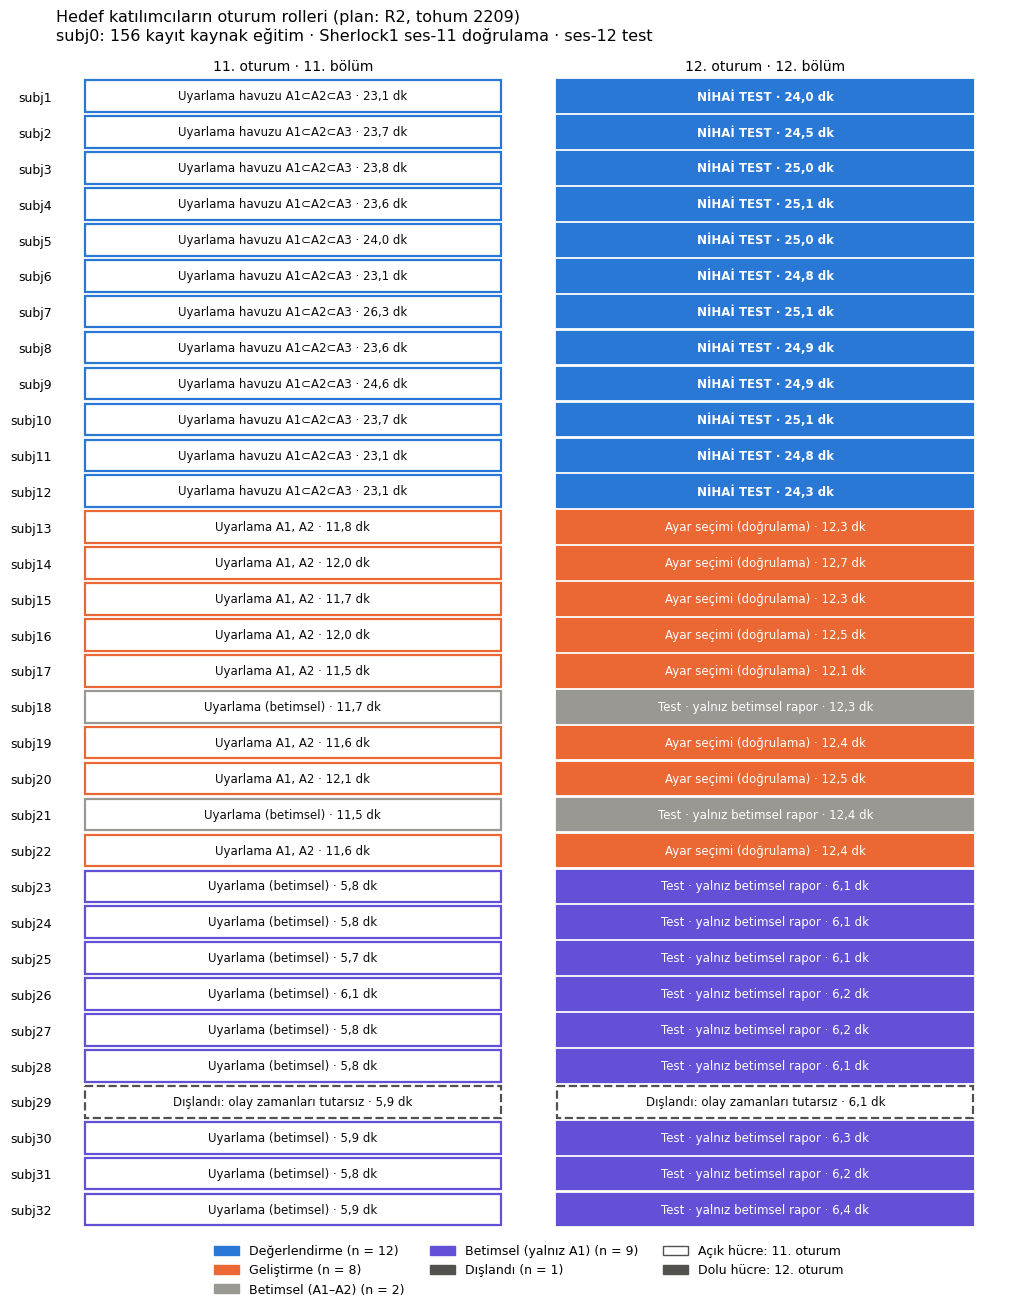

In [25]:
ROLE_STYLE = {
    "evaluation":     ("#2a78d6", "Değerlendirme"),
    "development":    ("#eb6834", "Geliştirme"),
    "descriptive_a2": ("#9a9893", "Betimsel (A1–A2)"),
    "descriptive_a1": ("#6250d6", "Betimsel (yalnız A1)"),
    "excluded":       ("#52514e", "Dışlandı"),
}
CELL_TEXT = {
    "eval_adapt": "Uyarlama havuzu A1⊂A2⊂A3", "eval_test": "NİHAİ TEST",
    "dev_adapt": "Uyarlama A1, A2", "dev_select": "Ayar seçimi (doğrulama)",
    "desc_adapt": "Uyarlama (betimsel)", "desc_test": "Test · yalnız betimsel rapor",
    "excluded": "Dışlandı: olay zamanları tutarsız",
}
role_minutes = access.set_index("record")["minutes"]

fig, ax = plt.subplots(figsize=(10, 13), layout="constrained")
for row, subject in enumerate(TARGET_SUBJECTS):
    color = ROLE_STYLE[ROLE_OF[subject]][0]
    for col, session in enumerate((11, 12)):
        rec = records.loc[records["subject"].eq(subject) & records["session"].eq(session)].iloc[0]
        solid = session == 12 and rec.split_role != "excluded"
        ax.add_patch(Rectangle((col + 0.06, row + 0.06), 0.88, 0.88, linewidth=1.6, edgecolor=color,
                               facecolor=color if solid else "white",
                               linestyle="--" if rec.split_role == "excluded" else "-"))
        minutes = f"{role_minutes[rec.record]:.1f}".replace(".", ",")
        ax.text(col + 0.5, row + 0.5, f"{CELL_TEXT[rec.split_role]} · {minutes} dk", ha="center",
                va="center", fontsize=8.5, color="white" if solid else "#0b0b0b",
                fontweight="bold" if rec.split_role == "eval_test" else "normal")
ax.set_xlim(0, 2)
ax.set_ylim(len(TARGET_SUBJECTS), 0)
ax.set_xticks([0.5, 1.5], ["11. oturum · 11. bölüm", "12. oturum · 12. bölüm"], fontsize=10)
ax.xaxis.tick_top()
ax.set_yticks([r + 0.5 for r in range(len(TARGET_SUBJECTS))], [f"subj{s}" for s in TARGET_SUBJECTS], fontsize=9)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title(f"Hedef katılımcıların oturum rolleri (plan: {PLAN}, tohum {SEED})\n"
             "subj0: 156 kayıt kaynak eğitim · Sherlock1 ses-11 doğrulama · ses-12 test",
             fontsize=11.5, loc="left", pad=14)
ax.legend(handles=[Patch(facecolor=c, edgecolor=c, label=f"{l} (n = {sum(r == k for r in ROLE_OF.values())})")
                   for k, (c, l) in ROLE_STYLE.items()]
                  + [Patch(facecolor="white", edgecolor="#52514e", label="Açık hücre: 11. oturum"),
                     Patch(facecolor="#52514e", edgecolor="#52514e", label="Dolu hücre: 12. oturum")],
          loc="upper center", bbox_to_anchor=(0.5, -0.005), ncol=3, frameon=False, fontsize=9)
fig.savefig(OUT / "role_map.png", dpi=200, bbox_inches="tight")
plt.show()

## Bölüm 7 Otomatik sızıntı testleri

Öneri Bölüm 2.2'deki sızıntı kuralları aşağıdaki testlerle denetlenir. Testlerden biri bile başarısız olursa hücre durur ve sonraki iş adımına geçilmez.

| Test | Denetlenen kural |
|---|---|
| T1 | Standart bölümler ve proje rolleri kayıt düzeyinde ayrıktır; her kaydın tek bir rolü vardır |
| T2 | Katılımcı rolleri ayrıktır; değerlendirme katılımcıları ayar seçimine girmez |
| T3 | Uyarlama alt kümeleri iç içedir (A1 ⊂ A2 ⊂ A3) ve yalnızca 11. oturumdan gelir |
| T4 | Arşive girecek her pencere kaydın içindedir, zaman damgası güvenilirdir ve etiketi sözlükle tutarlıdır |
| T5 | Hedef katılımcıların 11. / 12. oturum uyaranı, subj0'ın Sherlock1 11. / 12. oturum uyaranıyla aynıdır: dosya sırasıyla karşılaştırıldığında subj0'da olmayan kelime yoktur, eksik kelime en çok `MAX_MISSING_WORDS` kadardır |
| T6 | 12. oturum (test) uyaranı subj0'ın kaynak eğitim kayıtlarında yer almaz (8 kelimelik dizi örtüşmesi < %1) |
| T7 | Normalizasyon parametreleri yalnızca eğitim kayıtlarından hesaplanır (birim testi; gerçek parametreler Bölüm 8'de ayrıca denetlenir) |
| T8 | Kelime başlangıç zamanları dosya sırasında geriye gitmez. Seyrek çakışmalı kayıtlarda çakışma aralığındaki pencereler kullanılmaz; sistematik çakışmalı her katılımcı dışlama listesindedir |

Dışlanan katılımcılar T3–T5'e girmez.

In [26]:
class ChannelScaler:
    # Kanal bazında ortalama ve standart sapma; yalnızca verilen kayıtlardan hesaplanır.
    def __init__(self, n_channels=N_CHANNELS):
        self.n, self.s, self.ss = 0, np.zeros(n_channels), np.zeros(n_channels)
        self.fitted_on = set()

    def partial_fit(self, record_id, x):
        x = np.asarray(x, dtype=np.float64)
        self.n += x.shape[1]
        self.s += x.sum(axis=1)
        self.ss += (x ** 2).sum(axis=1)
        self.fitted_on.add(record_id)
        return self

    @property
    def mean(self):
        return self.s / self.n

    @property
    def std(self):
        return np.sqrt(np.maximum(self.ss / self.n - self.mean ** 2, 0))

    def transform(self, x):
        return (x - self.mean[:, None]) / self.std[:, None]


def assert_no_norm_leak(scaler, held_out_records):
    leaked = scaler.fitted_on & set(held_out_records)
    assert not leaked, f"Normalizasyon sızıntısı: {sorted(leaked)}"


def ngrams(sequence, n=8):
    return {tuple(sequence[i:i + n]) for i in range(len(sequence) - n + 1)}


def T1_records_have_one_role():
    assert records["record"].is_unique
    per_partition = records.groupby("partition")["record"].apply(set)
    for a in per_partition.index:
        for b in per_partition.index:
            if a < b:
                assert not per_partition[a] & per_partition[b], f"{a}–{b} ortak kayıt"
    assert windows.groupby("record")["split_role"].nunique().eq(1).all()
    return f"{len(records)} kayıt, {records['split_role'].nunique()} rol"


def T2_participant_roles_disjoint():
    groups = [set(roles[k]) for k in ("evaluation", "development", "descriptive_a1", "descriptive_a2")]
    groups.append(set(EXCLUDED_SUBJECTS))
    assert sum(len(g) for g in groups) == len(set().union(*groups)) == 32
    selection_subjects = set(records.loc[records["split_role"].isin(["dev_adapt", "dev_select"]), "subject"])
    assert not selection_subjects & set(roles["evaluation"])
    return f"değerlendirme {len(roles['evaluation'])} · geliştirme {len(roles['development'])}"


def T3_adaptation_subsets_nested():
    level_cols = [f"in_{lvl}" for lvl in LEVEL_MINUTES] + ["in_A_all"]
    in_any = windows[level_cols].any(axis=1)
    assert windows.loc[in_any, "session"].eq(11).all() and windows.loc[in_any, "subject"].ge(1).all()
    assert not windows.loc[in_any, "split_role"].isin(["eval_test", "dev_select", "desc_test"]).any()
    assert (windows["in_A1"] <= windows["in_A2"]).loc[windows["participant_role"].ne("descriptive_a1")].all()
    assert (windows["in_A2"] <= windows["in_A3"]).loc[windows["participant_role"].eq("evaluation")].all()
    return f"{int(in_any.sum())} uyarlama penceresi"


def T4_windows_in_bounds_and_labelled():
    archived = windows.loc[windows["fits"] & windows["in_vocab"] & windows["timing_ok"]
                           & windows["split_role"].ne("excluded")]
    n_samples = archived["record"].map({r: h["n_samples"] for r, h in headers.items()})
    assert archived["start"].ge(0).all() and archived["stop"].le(n_samples).all()
    assert (archived["label"].map(lambda k: VOCAB[k]) == archived["word"]).all()
    return f"{len(archived)} pencere"


MAX_MISSING_WORDS = 10   # bazı olay dosyalarında kapanış duyurusu (6 kelime) bulunmuyor


def T5_same_stimulus_across_participants():
    missing_by_record = {}
    for session in (11, 12):
        reference = sequences[record_of(0, "Sherlock1", session)]
        targets_in_session = records.loc[records["subject"].ge(1) & records["session"].eq(session)
                                         & records["split_role"].ne("excluded"), "record"]
        for rec in targets_in_session:
            other = sequences[rec]
            ops = [] if other == reference else [
                op for op in difflib.SequenceMatcher(None, reference, other, autojunk=False).get_opcodes()
                if op[0] != "equal"]
            extra = sum(j2 - j1 for tag, _, _, j1, j2 in ops if tag in ("insert", "replace"))
            missing = sum(i2 - i1 for tag, i1, i2, _, _ in ops if tag in ("delete", "replace"))
            assert extra == 0, f"{rec}: subj0'da olmayan {extra} kelime"
            assert missing <= MAX_MISSING_WORDS, f"{rec}: {missing} kelime eksik"
            missing_by_record[rec] = missing
    incomplete = {r: m for r, m in missing_by_record.items() if m}
    return (f"{len(missing_by_record)} kayıt; fazla kelime yok; eksik kelimeli kayıt {len(incomplete)} "
            f"(en çok {max(incomplete.values(), default=0)})")


def T6_test_stimulus_not_in_source_train():
    worst = {}
    for session in (11, 12):
        held_out = ngrams(sequences[record_of(0, "Sherlock1", session)])
        for rec in records.loc[records["split_role"].eq("src_train"), "record"]:
            share = len(held_out & ngrams(sequences[rec])) / len(held_out)
            worst[(session, rec)] = share
    (session, rec), share = max(worst.items(), key=lambda kv: kv[1])
    assert share < 0.01, f"ses-{session} uyaranı {rec} ile %{100 * share:.1f} örtüşüyor"
    return f"en yüksek örtüşme %{100 * share:.2f} ({rec}, ses-{session})"


def T7_scaler_uses_only_train():
    rng = np.random.default_rng(0)
    data = {"train": rng.normal(size=(3, 500)), "test": rng.normal(10, 5, size=(3, 500))}
    scaler = ChannelScaler(3).partial_fit("train", data["train"])
    np.testing.assert_allclose(scaler.mean, data["train"].mean(axis=1))
    assert_no_norm_leak(scaler, ["test"])
    try:
        assert_no_norm_leak(ChannelScaler(3).partial_fit("test", data["test"]), ["test"])
    except AssertionError:
        return "sızıntı denetimi çalışıyor"
    raise AssertionError("Sızıntı denetimi test kaydını yakalamadı")


def T8_event_times_monotonic():
    severe = event_integrity.loc[event_integrity["n_backward_steps"].gt(MAX_BACKWARD_STEPS)
                                 | event_integrity["n_nan_onsets"].gt(0)]
    unexpected = set(severe["subject"]) - set(EXCLUDED_SUBJECTS)
    assert not unexpected, f"Sistematik zaman çakışması var ama dışlanmamış katılımcı: {sorted(unexpected)}"
    for conflict in timing_conflicts.itertuples():
        in_span = (windows["record"].eq(conflict.record)
                   & windows["onset"].le(conflict.span_end_s)
                   & (windows["onset"] + WINDOW_SEC).gt(conflict.span_start_s))
        assert not windows.loc[in_span, "timing_ok"].any(), f"{conflict.record}: çakışma aralığı temizlenmemiş"
    minor = event_integrity.loc[event_integrity["n_backward_steps"].between(1, MAX_BACKWARD_STEPS)]
    excluded = ", ".join(f"subj{s}" for s in sorted(set(severe["subject"]))) or "yok"
    return (f"dışlanan: {excluded} · seyrek çakışma temizlenen kayıt: {len(minor)} "
            f"({int((~windows['timing_ok']).sum())} kelime)")

results = []
for test in (T1_records_have_one_role, T2_participant_roles_disjoint, T3_adaptation_subsets_nested,
             T4_windows_in_bounds_and_labelled, T5_same_stimulus_across_participants,
             T6_test_stimulus_not_in_source_train, T7_scaler_uses_only_train, T8_event_times_monotonic):
    try:
        results.append({"test": test.__name__, "result": "PASS", "detail": test()})
    except AssertionError as error:
        results.append({"test": test.__name__, "result": "FAIL", "detail": str(error)})

leak_report = pd.DataFrame(results)
leak_report.to_csv(OUT / "leakage_tests.csv", index=False)
display(leak_report)
assert leak_report["result"].eq("PASS").all(), "Sızıntı testi başarısız: kaynağı bulunmadan devam edilmez"

,test,result,detail
0,T1_records_have_one_role,PASS,"226 kayıt, 10 rol"
1,T2_participant_roles_disjoint,PASS,değerlendirme 12 · geliştirme 8
2,T3_adaptation_subsets_nested,PASS,25305 uyarlama penceresi
3,T4_windows_in_bounds_and_labelled,PASS,364643 pencere
4,T5_same_stimulus_across_participants,PASS,62 kayıt; fazla kelime yok; eksik kelimeli kay...
5,T6_test_stimulus_not_in_source_train,PASS,en yüksek örtüşme %0.41 (sub-0_ses-10_task-She...
6,T7_scaler_uses_only_train,PASS,sızıntı denetimi çalışıyor
7,T8_event_times_monotonic,PASS,dışlanan: subj29 · seyrek çakışma temizlenen k...


## Bölüm 8 Kayıt düzeyi kalite denetimi, pencere arşivi ve normalizasyon parametreleri

Her kayıt bir kez indirilir ve aynı geçişte üç iş yapılır:

1. **Kalite denetimi (Öneri 2.2/1, R5):** eksik (NaN) ve sonsuz (Inf) değerler, zaman boyunca değişmeyen (düz) kanallar ve kendi kanal türü içinde standart sapması aykırı olan kanallar.
2. **Pencere arşivi (Öneri 2.2/5):** 50 kelimelik sözlüğe ait, kayda tam sığan pencereler 16 bitlik kayan noktalı biçimde, kayıt başına bir dosya olarak kaydedilir. MEG değerleri SI biriminde ~1e-11 düzeyindedir; float16'nın en küçük değeri ~6e-8 olduğundan doğrudan dönüştürme tüm sinyali sıfırlar. Bu nedenle değerler önce sabit birim katsayılarıyla manyetometrelerde pT’ye, gradiyometrelerde pT/cm’ye çevrilir. Daha küçük birimler (fT) seçildiğinde, yavaş değişen büyük alanlar içeren kayıtlarda değerler float16'nın üst sınırını (65.504) aşmaktadır; pT ile üst sınır 65 nT’ye karşılık gelir. Katsayılar veriden hesaplanmadığı için sızıntı yaratmaz.
3. **Normalizasyon parametreleri (Öneri 2.2/4):** kanal ortalaması ve standart sapması yalnızca subj0'ın kaynak eğitim kayıtlarından (`src_train`) hesaplanır ve sonraki iş paketlerinde doğrulama ve test verisine sabit uygulanır. Varsayılan olarak bu değerler, hedef katılımcılar dahil bütün katılımcılara ve bütün koşullara (A0 dahil) sabit uygulanır. Hedef katılımcılarda uyarlama verisinden hesaplanan kişiye özgü normalizasyon, İP-4'te yalnızca geliştirme katılımcılarında sınanabilir; varsayılan değiştirilirse sapma kaydına yazılır.

İşlenen kaydın ham dosyası diskten silinir. Hücre kaldığı yerden devam eder.

In [27]:
UNIT_SCALE = np.where(channel_types == "mag", 1e12, 1e10).astype(np.float32)[:, None] # T→pT, T/m→pT/cm
FLOAT16_MAX = float(np.finfo(np.float16).max)
KEEP_RAW = False


def to_archive(x):
    scaled = x.astype(np.float32) * UNIT_SCALE
    return scaled.astype(np.float16), scaled


def record_qc(x_scaled):
    # x_scaled: (kanal, zaman), pT / pT/cm
    nan_count = int(np.isnan(x_scaled).sum())
    inf_count = int(np.isinf(x_scaled).sum())
    clean = np.nan_to_num(x_scaled, nan=0.0, posinf=0.0, neginf=0.0)
    std = clean.std(axis=1)
    flat = np.flatnonzero(np.ptp(clean, axis=1) == 0)
    robust_z = np.zeros(len(std))
    for ch_type in ("mag", "grad"):
        sel = channel_types == ch_type
        log_std = np.log(std[sel] + 1e-12)
        mad = np.median(np.abs(log_std - np.median(log_std))) * 1.4826
        robust_z[sel] = (log_std - np.median(log_std)) / (mad if mad > 0 else 1)
    return {
        "nan": nan_count, "inf": inf_count,
        "flat_channels": [channel_names[i] for i in flat],
        "outlier_channels": [channel_names[i] for i in np.flatnonzero(np.abs(robust_z) > 5) if i not in flat],
        "max_abs_mag_pT": float(np.abs(clean[channel_types == "mag"]).max()),
        "max_abs_grad_pTcm": float(np.abs(clean[channel_types == "grad"]).max()),
        "float16_overflow": int((np.abs(clean) > FLOAT16_MAX).sum()),
    }


# Dönüşümün pilot pencerede kayıpsız sayılabileceğini doğrula
raw_window = meg_signal.numpy()
print("Ölçeksiz float16'da sıfıra yuvarlanan değer oranı:", float((raw_window.astype(np.float16) == 0).mean()))
archived_window, scaled_window = to_archive(raw_window)
relative_error = np.abs(archived_window.astype(np.float32) - scaled_window).max() / np.abs(scaled_window).max()
print(f"Ölçekli float16 göreli hata: {relative_error:.1e}")
assert relative_error < 1e-3

Ölçeksiz float16'da sıfıra yuvarlanan değer oranı: 1.0
Ölçekli float16 göreli hata: 2.9e-04


In [28]:
qc_path = OUT / "quality_report.csv"
scaler_path = OUT / "normalization_sums_subj0_train.npz"
qc_rows = pd.read_csv(qc_path).set_index("record").to_dict("index") if qc_path.exists() else {}

source_scaler = ChannelScaler()
if scaler_path.exists():
    saved = np.load(scaler_path, allow_pickle=True)
    source_scaler.n, source_scaler.s, source_scaler.ss = int(saved["n"]), saved["s"], saved["ss"]
    source_scaler.fitted_on = set(saved["fitted_on"].tolist())

archive_windows = windows.loc[windows["fits"] & windows["in_vocab"] & windows["timing_ok"]& windows["split_role"].ne("excluded")].copy()
archive_windows["archive_row"] = archive_windows.groupby("record").cumcount()
archive_windows["archive_file"] = archive_windows["record"] + ".npy"

done = {r for r in qc_rows if (ARCHIVE_DIR / f"{r}.npy").exists()}
todo = records.loc[~records["record"].isin(done)]
for rec in tqdm(todo.itertuples(), total=len(todo), desc="Kalite denetimi ve arşiv"):
    local = hf_file(rec.meg_repo, rec.meg_path)
    with h5py.File(local, "r") as h5:
        x = h5["data"][:]
    archived, scaled = to_archive(x)
    qc_rows[rec.record] = record_qc(scaled)

    rows = archive_windows.loc[archive_windows["record"].eq(rec.record)]
    batch = np.stack([archived[:, s:e] for s, e in zip(rows["start"], rows["stop"])]) if len(rows) else \
        np.empty((0, N_CHANNELS, int(WINDOW_SEC * EXPECTED_SFREQ)), dtype=np.float16)
    np.save(ARCHIVE_DIR / f"{rec.record}.npy", batch)

    if rec.split_role == "src_train" and rec.record not in source_scaler.fitted_on:
        source_scaler.partial_fit(rec.record, np.nan_to_num(scaled))
        np.savez(scaler_path, n=source_scaler.n, s=source_scaler.s, ss=source_scaler.ss,
                 fitted_on=np.array(sorted(source_scaler.fitted_on)), unit="pT")

    pd.DataFrame.from_dict(qc_rows, orient="index").rename_axis("record").to_csv(qc_path)
    del x, archived, scaled
    if not KEEP_RAW:
        Path(local).resolve().unlink(missing_ok=True)
        Path(local).unlink(missing_ok=True)

archive_windows.drop(columns=["fits", "in_vocab", "timing_ok"]).to_parquet(OUT / "window_manifest.parquet")
np.savez(OUT / "normalization_subj0_train.npz", mean=source_scaler.mean, std=source_scaler.std,
         fitted_on=np.array(sorted(source_scaler.fitted_on)), unit="pT")
print("Arşivlenen pencere:", len(archive_windows))

Kalite denetimi ve arşiv: 0it [00:00, ?it/s]

Arşivlenen pencere: 364643


In [29]:
qc = pd.read_csv(qc_path).merge(records[["record", "subject", "split_role"]], on="record")
for column in ("flat_channels", "outlier_channels"):
    qc[f"n_{column}"] = qc[column].map(lambda v: len(ast.literal_eval(v)) if isinstance(v, str) else len(v))

print("Kalite denetimi özeti")
display(qc[["nan", "inf", "float16_overflow", "n_flat_channels", "n_outlier_channels"]].agg(["sum", "max"]))
flagged = qc.loc[qc[["nan", "inf", "float16_overflow", "n_flat_channels"]].sum(axis=1).gt(0)
                 | qc["n_outlier_channels"].gt(0)]
print("İncelenecek kayıt:", len(flagged))
display(flagged[["record", "nan", "inf", "float16_overflow", "flat_channels", "outlier_channels"]])

# Normalizasyon parametreleri yalnızca kaynak eğitim kayıtlarından
train_records = set(records.loc[records["split_role"].eq("src_train"), "record"])
assert source_scaler.fitted_on == train_records, "Normalizasyon tüm eğitim kayıtlarını kapsamıyor"
assert_no_norm_leak(source_scaler, set(records["record"]) - train_records)
assert qc["nan"].eq(0).all() and qc["inf"].eq(0).all(), "NaN/Inf içeren kayıt var"
assert qc["float16_overflow"].eq(0).all(), "float16 aralığını aşan değer var"
print("Normalizasyon parametreleri yalnızca", len(train_records), "kaynak eğitim kaydından hesaplandı.")

Kalite denetimi özeti


,nan,inf,float16_overflow,n_flat_channels,n_outlier_channels
sum,0,0,0,0,60
max,0,0,0,0,9


İncelenecek kayıt: 16


,record,nan,inf,float16_overflow,flat_channels,outlier_channels
21,sub-0_ses-6_task-Sherlock2_run-1,0,0,0,[],['MEG2631']
22,sub-0_ses-7_task-Sherlock2_run-1,0,0,0,[],['MEG2631']
32,sub-0_ses-5_task-Sherlock3_run-1,0,0,0,[],['MEG2631']
51,sub-0_ses-12_task-Sherlock4_run-1,0,0,0,[],"['MEG2522', 'MEG2642']"
52,sub-0_ses-1_task-Sherlock5_run-1,0,0,0,[],"['MEG0921', 'MEG1211', 'MEG2521', 'MEG2522', '..."
53,sub-0_ses-2_task-Sherlock5_run-1,0,0,0,[],"['MEG2631', 'MEG2641', 'MEG2642']"
54,sub-0_ses-3_task-Sherlock5_run-1,0,0,0,[],"['MEG0921', 'MEG1211']"
62,sub-0_ses-11_task-Sherlock5_run-1,0,0,0,[],"['MEG0931', 'MEG1211', 'MEG1231', 'MEG2531', '..."
63,sub-0_ses-12_task-Sherlock5_run-1,0,0,0,[],"['MEG0921', 'MEG1211', 'MEG1231', 'MEG2521', '..."
65,sub-0_ses-14_task-Sherlock5_run-1,0,0,0,[],"['MEG0921', 'MEG0931', 'MEG1211', 'MEG1231', '..."


Normalizasyon parametreleri yalnızca 156 kaynak eğitim kaydından hesaplandı.


### Manifest ile arşivin tutarlılığı

Manifestteki her satırın arşivde doğru pencereye işaret ettiği denetlenir: her kayıt dosyasının boyutu, satır sayısı ve satır numaraları manifestle karşılaştırılır. Ayrıca pilot kaydın ham dosyası hâlâ diskte olduğu için, rastgele 20 pencerenin arşivdeki değeri ham veriden yeniden hesaplanan değerle birebir karşılaştırılır.

In [30]:
manifest_check = pd.read_parquet(OUT / "window_manifest.parquet")
n_points = int(WINDOW_SEC * EXPECTED_SFREQ)
problems = []
for record_id in tqdm(records["record"], desc="Manifest–arşiv"):
    arr = np.load(ARCHIVE_DIR / f"{record_id}.npy", mmap_mode="r")
    rows = np.sort(manifest_check.loc[manifest_check["record"].eq(record_id), "archive_row"].to_numpy())
    if arr.shape[1:] != (N_CHANNELS, n_points):
        problems.append((record_id, "pencere boyutu", arr.shape))
    elif len(rows) != arr.shape[0] or not np.array_equal(rows, np.arange(arr.shape[0])):
        problems.append((record_id, "satırlar", len(rows), arr.shape[0]))

assert manifest_check["split_role"].ne("excluded").all(), "Dışlanan kayıt manifestte"
assert manifest_check[["record", "archive_row"]].duplicated().sum() == 0, "Tekrarlanan satır"
assert not problems, problems[:5]

pilot_record = "sub-{}_ses-{}_task-{}_run-{}".format(*pilot_key)
pilot_arr = np.load(ARCHIVE_DIR / f"{pilot_record}.npy", mmap_mode="r")
with h5py.File(pilot_h5_path, "r") as h5:
    for r in manifest_check.loc[manifest_check["record"].eq(pilot_record)].sample(20, random_state=SEED).itertuples():
        expected = (h5["data"][:, r.start:r.stop].astype(np.float32) * UNIT_SCALE).astype(np.float16)
        np.testing.assert_array_equal(pilot_arr[r.archive_row], expected)

print(f"Manifest ile arşiv tutarlı: {len(manifest_check):,} pencere, {len(records)} dosya; "
      "pilot kayıtta 20 pencere ham veriyle birebir aynı.")

Manifest–arşiv:   0%|          | 0/226 [00:00<?, ?it/s]

Manifest ile arşiv tutarlı: 364,643 pencere, 226 dosya; pilot kayıtta 20 pencere ham veriyle birebir aynı.


In [31]:
# Aykırı kanalların büyüklüğü: kanal std'si / aynı türdeki kanalların medyan std'si
flagged = qc.loc[qc["n_outlier_channels"].gt(0)]
rows = []
for rec in tqdm(list(flagged.itertuples()), desc="Aykırı kanallar"):
    arr = np.load(ARCHIVE_DIR / f"{rec.record}.npy", mmap_mode="r")
    if len(arr) == 0:
        continue
    sample = np.asarray(arr[::max(1, len(arr) // 200)], dtype=np.float32)   # ~200 pencere
    std = sample.std(axis=(0, 2))
    for name in ast.literal_eval(rec.outlier_channels):
        i = channel_names.index(name)
        same_type = channel_types == channel_types[i]
        rows.append({"record": rec.record, "channel": name, "type": channel_types[i],
                     "std_ratio": round(float(std[i] / np.median(std[same_type])), 2)})

outlier_detail = pd.DataFrame(rows)
outlier_detail.to_csv(OUT / "outlier_channels.csv", index=False)
display(outlier_detail.sort_values("std_ratio"))
display(outlier_detail.groupby("channel").size().sort_values(ascending=False).rename("kayıt sayısı").to_frame().T)

Aykırı kanallar:   0%|          | 0/16 [00:00<?, ?it/s]

,record,channel,type,std_ratio
58,sub-14_ses-11_task-Sherlock1_run-1,MEG2141,mag,0.37
57,sub-14_ses-11_task-Sherlock1_run-1,MEG2131,mag,0.37
59,sub-14_ses-11_task-Sherlock1_run-1,MEG2541,mag,0.43
55,sub-0_ses-7_task-Sherlock9_run-1,MEG0921,mag,0.59
11,sub-0_ses-1_task-Sherlock5_run-1,MEG2633,grad,0.60
32,sub-0_ses-14_task-Sherlock5_run-1,MEG0931,mag,0.69
15,sub-0_ses-2_task-Sherlock5_run-1,MEG2641,mag,0.73
31,sub-0_ses-14_task-Sherlock5_run-1,MEG0921,mag,0.74
43,sub-0_ses-15_task-Sherlock5_run-1,MEG2532,grad,0.76
45,sub-0_ses-15_task-Sherlock5_run-1,MEG2622,grad,0.79


channel,MEG2631,MEG2641,MEG1211,MEG2642,MEG0921,MEG2521,MEG2621,MEG2522,MEG1231,MEG2531,MEG0931,MEG2523,MEG1412,MEG2131,MEG2141,MEG2622,MEG2541,MEG2532,MEG2633
kayıt sayısı,11,7,6,5,5,4,3,3,3,3,2,1,1,1,1,1,1,1,1


In [32]:
log_deviation(
    "aykiri_kanallar", "2.2/1, R5",
    "Bozuk veya gürültülü kanallar otomatik tespit edilir; gerekirse interpolasyon ya da ortak kanal kümesi uygulanır",
    f"{outlier_detail['record'].nunique()} kayıtta {len(outlier_detail)} kanal aykırı olarak işaretlendi; "
    "hiçbir kanal dışlanmadı veya interpole edilmedi, 306 kanal tüm kayıtlarda aynı sırayla kullanılır",
    f"Pencere düzeyinde kanal std'sinin aynı türdeki kanalların medyanına oranı "
    f"{outlier_detail['std_ratio'].min():.2f}–{outlier_detail['std_ratio'].max():.2f} aralığındadır "
    "(önceden belirlenen 0,1–10 eşiklerinin içinde); düz, NaN veya Inf içeren kanal yoktur",
)

### Aykırı kanalların değerlendirilmesi (R5)

Kalite denetimi 16 kayıtta (15'i subj0, biri sub-14'ün 11. oturumu) toplam 60 kanalı aykırı olarak işaretlemiştir. Sapmanın büyüklüğü, her kanalın pencere düzeyindeki standart sapmasının aynı türdeki kanalların medyanına oranıyla ölçülmüştür. Önceden belirlenen kurala göre oran 0,1'in altında veya 10'un üstündeyse kanal interpolasyon için değerlendirilecek, aradaki değerlerde tutulacaktı.

* Bütün oranlar 0,37–2,65 aralığındadır; çoğu 0,6–1,1 arasındadır. Pencere düzeyinde bu kanallar tipik kanallardan belirgin biçimde ayrılmamaktadır. Aykırılık, kaydın tamamında görülen yavaş ve büyük genlikli değişimlerden kaynaklanmaktadır.
* En yüksek oran 2,65'tir (subj0, Sherlock5 ses-2, MEG2642).
* sub-14'ün üç manyetometresinin (MEG2131, MEG2141, MEG2541) oranı ~0,4'tür; bu kanallar diğerlerinden daha düşük genliklidir.
* MEG2631 (11 kayıt) ve MEG2641 (7 kayıt) en sık işaretlenen kanallardır; subj0'da bu sensörler belirli dönemlerde daha gürültülüdür.

**Karar:** Hiçbir kanal dışlanmamış veya interpole edilmemiştir; 306 kanal tüm kayıtlarda aynı sırayla kullanılır. Karar `deviations.csv` dosyasına kaydedilmiştir. Ayrıntılı tablo: `outlier_channels.csv`.


Aykırı kanal listesi otomatik bir işarettir; kanalı dışlama kararı değildir. Veri ekibi bozuk kanalları SSS öncesinde işlediği (`bads`) için bu listenin boş veya kısa olması beklenir. Listede kanal bulunan kayıtlar İP-2 başlamadan incelenir; dışlama veya interpolasyon kararı (R5) bu bölümde gerekçesiyle kaydedilir.

## Bölüm 9 Koşu süresi ve bellek ön ölçümü

Öneri Bölüm 2.7'deki hesaplama ihtiyacı (~380 GPU-saat) şu varsayımlara dayanır: subj0 eğitim verisinde ~300 bin pencere, kaynak eğitim başına ~2 saat, uyarlama koşusu başına ~2 dakika. Bu bölüm, gerçek pencere sayısını, arşiv boyutunu, arşivden okuma hızını ve M1 başlangıç yapılandırmasının (3 evrişim bloğu; 32/64/128 kanal; çekirdek 7/5/3; GELU; dropout 0,2) bir eğitim adımının süresini ölçer.

In [33]:
import torch
from torch import nn
import shutil

# Okuma hızı eğitimdeki gibi yerel diskten ölçülür: arşivi Drive'dan Colab diskine kopyala
LOCAL_ARCHIVE = Path("/content/windows_500ms_local")
read_dir = ARCHIVE_DIR
if USE_DRIVE:
    # Eksik veya yarım kopyalanmış dosyaları tamamla (boyutu Drive'dakinden farklı olanlar yeniden kopyalanır)
    LOCAL_ARCHIVE.mkdir(exist_ok=True)
    for src in tqdm(sorted(ARCHIVE_DIR.glob("*.npy")), desc="Arşiv yerel diske"):
        dst = LOCAL_ARCHIVE / src.name
        if not dst.exists() or dst.stat().st_size != src.stat().st_size:
            shutil.copy2(src, dst)
    read_dir = LOCAL_ARCHIVE

manifest_df = pd.read_parquet(OUT / "window_manifest.parquet")
src_train = manifest_df.loc[manifest_df["record"].isin(train_records)]
archive_gb = sum(p.stat().st_size for p in ARCHIVE_DIR.glob("*.npy")) / 1e9

# Arşivden rastgele okuma hızı
sample = src_train.sample(2048, random_state=SEED)
start = time.perf_counter()
for file, group in sample.groupby("archive_file"):
    np.asarray(np.load(read_dir / file, mmap_mode="r")[np.sort(group["archive_row"].to_numpy())])
read_rate = len(sample) / (time.perf_counter() - start)

# M1 başlangıç yapılandırmasıyla eğitim adımı süresi
def m1_block(c_in, c_out, k):
    return nn.Sequential(nn.Conv1d(c_in, c_out, k, padding=k // 2), nn.BatchNorm1d(c_out), nn.GELU(), nn.Dropout(0.2))

device = "cuda" if torch.cuda.is_available() else "cpu"
model = nn.Sequential(m1_block(N_CHANNELS, 32, 7), m1_block(32, 64, 5), m1_block(64, 128, 3),
                      nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Linear(128, 50)).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)
batch_x = torch.randn(256, N_CHANNELS, int(WINDOW_SEC * EXPECTED_SFREQ), device=device)
batch_y = torch.randint(0, 50, (256,), device=device)
if device == "cuda":
    torch.cuda.reset_peak_memory_stats()
for step in range(25):
    if step == 5:
        if device == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
    optimizer.zero_grad()
    nn.functional.cross_entropy(model(batch_x), batch_y).backward()
    optimizer.step()
if device == "cuda":
    torch.cuda.synchronize()
step_time = (time.perf_counter() - start) / 20

estimate = {
    "device": torch.cuda.get_device_name() if device == "cuda" else "cpu",
    "subj0_train_windows": int(len(src_train)),
    "archive_size_gb": round(archive_gb, 2),
    "archive_read_windows_per_s": round(read_rate),
    "m1_parameters": sum(p.numel() for p in model.parameters()),
    "m1_step_time_s_batch256": round(step_time, 4),
    "m1_epoch_compute_min_est": round(len(src_train) / 256 * step_time / 60, 1),
    "m1_epoch_read_min_est": round(len(src_train) / read_rate / 60, 1),
    "gpu_peak_memory_gb": round(torch.cuda.max_memory_allocated() / 1e9, 2) if device == "cuda" else None,
}
(OUT / "benchmark.json").write_text(json.dumps(estimate, indent=2, ensure_ascii=False))
estimate

Arşiv yerel diske:   0%|          | 0/226 [00:00<?, ?it/s]

{'device': 'Tesla T4',
 'subj0_train_windows': 307329,
 'archive_size_gb': 27.9,
 'archive_read_windows_per_s': 260,
 'm1_parameters': 110482,
 'm1_step_time_s_batch256': 0.0128,
 'm1_epoch_compute_min_est': 0.3,
 'm1_epoch_read_min_est': 19.7,
 'gpu_peak_memory_gb': 0.17}

### Güncellenmiş hesaplama planı (İP-1 başarı ölçütü)

Ön ölçüm, Tesla T4 GPU üzerinde ve Colab yerel diskinden yapılmıştır.

| | Öneri varsayımı | Ölçüm |
|---|---|---|
| subj0 kaynak eğitim penceresi | ~300 bin | 307.329 |
| Pencere arşivi (tüm kayıtlar) | ~23 GB (yalnız subj0 eğitimi) | 27,9 GB |
| M1 hesaplama süresi | — | 0,2 dk/epoch (batch 256) |
| M1 GPU belleği | — | 0,17 GB |
| Rastgele sırayla arşivden okuma | — | 300 pencere/sn (17,1 dk/epoch) |

**Bulgu:** Kaynak eğitimde darboğaz GPU hesaplaması değil, veri okumadır. Pencereler rastgele sırayla okunduğunda GPU zamanın büyük bölümünde boş beklemekte; 30 epoch'luk bir kaynak eğitim ~8,5 saate çıkmaktadır. Bu durum, öneride kaynak eğitim başına varsayılan ~2 saatin ve toplam ~380 GPU-saatlik bütçenin aşılmasına yol açar.

**Plan güncellemesi:**
1. İP-2'de model eğitimine başlamadan önce veri yükleyici, sıralı blok okuma ve blok içi karıştırma ile yeniden tasarlanacak ve epoch süresi yeniden ölçülecektir. Hedef: epoch başına okuma süresinin hesaplama süresinin en çok birkaç katı olması.
2. Hedeflenen okuma hızına ulaşılamazsa, subj0 eğitim verisinin (~23,5 GB) belleğe alınabildiği yüksek RAM'li çalışma zamanı kullanılacaktır.
3. Uyarlama koşuları (katılımcı başına en çok ~1.300 pencere) bellekte yürütüleceği için koşu başına ~2 dakikalık varsayım geçerliliğini korumaktadır.
4. M2 (CNN–Transformer) için hesaplama süresi ve bellek ölçümü İP-3'te tekrarlanacaktır; GPU-saat bütçesi bu ölçümle kesinleştirilecektir. Bütçe yetmezse R3'teki öncelik sırası uygulanır.

## Bölüm 10 İP-1 özeti

İP-1'in başarı ölçütü (Öneri 3.1): veri erişim tablosu ile kalite raporunun tamamlanması, tüm sızıntı testlerinin geçmesi ve ön ölçümle güncellenmiş hesaplama planının hazırlanması.

In [34]:
outputs = ["run_info.json", "data_access.csv", "event_integrity.csv", "timing_conflicts.csv",
           "class_frequencies.csv", "participant_roles.json", "adaptation_subsets.csv", "role_map.png",
           "leakage_tests.csv", "quality_report.csv", "outlier_channels.csv", "window_manifest.parquet",
           "normalization_subj0_train.npz", "benchmark.json", "deviations.csv"]
display(pd.DataFrame({"dosya": outputs, "var": [(OUT / f).exists() for f in outputs]}))

checklist = {
    "Veri erişim tablosu": (OUT / "data_access.csv").exists(),
    "Kalite raporu (226 kayıt)": len(pd.read_csv(qc_path)) == len(records),
    "Tüm sızıntı testleri geçti": leak_report["result"].eq("PASS").all(),
    "Manifest ile arşiv tutarlı": not problems,
    "Ön ölçüm tamamlandı": (OUT / "benchmark.json").exists(),
}
display(pd.Series(checklist, name="tamamlandı").to_frame())

print("Öneriden sapmalar")
display(pd.DataFrame(DEVIATIONS.values()))

,dosya,var
0,run_info.json,True
1,data_access.csv,True
2,event_integrity.csv,True
3,timing_conflicts.csv,True
4,class_frequencies.csv,True
5,participant_roles.json,True
6,adaptation_subsets.csv,True
7,role_map.png,True
8,leakage_tests.csv,True
9,quality_report.csv,True


,tamamlandı
Veri erişim tablosu,True
Kalite raporu (226 kayıt),True
Tüm sızıntı testleri geçti,True
Manifest ile arşiv tutarlı,True
Ön ölçüm tamamlandı,True


Öneriden sapmalar


,section,proposal,implementation,rationale
0,"2.1 (veri keşfi), 2.2",Eksik veya bozuk kayıtlar veri keşfinde belirl...,7 kayıtta olay zamanlarının çakıştığı aralıkla...,Bu kayıtlarda kelime başlangıç zamanı yalnızca...
1,R2,~10 dakikalık gruptaki katılımcılar A1 düzeyin...,subj29 tüm analizlerden çıkarıldı,Olay dosyalarında (ses-11 ve ses-12) kelime ba...
2,R2,~20 dakikalık gruptan sabit tohumla 8 geliştir...,"Seçilmeyen katılımcılar (subj18, subj21) A1–A2...",Öneri bu katılımcılara rol tanımlamamaktadır
3,"2.1, R2","Geliştirme katılımcılarında uyarlama, değerlen...",Geliştirme katılımcılarında ayarlar A1 ve A2 d...,R2'de geliştirme katılımcılarının 11. oturumu ...
4,R2,~10 dakikalık gruptaki katılımcılar A1 düzeyin...,subj24 için 5 dakikalık A1 alt kümesi oluşturu...,"Kayıt, ilk kelimeden itibaren 5 dakikaya ulaşm..."
5,"2.2/1, R5",Bozuk veya gürültülü kanallar otomatik tespit ...,16 kayıtta 60 kanal aykırı olarak işaretlendi;...,Pencere düzeyinde kanal std'sinin aynı türdeki...


In [35]:
if USE_DRIVE:
    drive.flush_and_unmount()
    print("Drive'a yazma tamamlandı.")

Drive'a yazma tamamlandı.
